In [1]:
import functools
import glob
import os
import re
import time
import traceback
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr

import dask
from dask.distributed import Client, LocalCluster, progress, wait

In [28]:
from __future__ import annotations

import dataclasses
import warnings
from pathlib import Path
from typing import Optional, Sequence

import numpy as np
from scipy import signal

try:
    import xarray as xr
except ImportError:
    xr = None


EARTH_RADIUS_KM = 6371.0088


# ============================================================================
# Result containers
# ============================================================================

@dataclasses.dataclass
class AliasSegmentSpectrum:
    """
    Alias-decomposition result for one along-track/cross-track Unsmoothed
    SWOT segment.

    All PSDs use the same along-track wavenumber axis and have units of
    SSH^2 / (cycles/km).

    total_psd = direct_psd + aliased_psd
    """

    swath: str
    segment_index: int

    wavenumber: np.ndarray

    direct_psd: np.ndarray
    aliased_psd: np.ndarray
    total_psd: np.ndarray

    lat_mean: float
    lat_min: float
    lat_max: float
    lon_mean: float

    along_track_distance_start_km: float
    along_track_distance_end_km: float

    n_lines: int
    n_pixels: int

    valid_fraction: float
    gap_filled: bool

    # Useful diagnostics
    direct_energy: Optional[float] = None
    aliased_energy: Optional[float] = None
    aliased_fraction: Optional[float] = None
    gap_fraction: Optional[float] = None


@dataclasses.dataclass
class AliasPassSpectrumResult:
    """All alias-decomposition segments for one SWOT swath."""

    swath: str

    wavenumber: np.ndarray

    mean_direct_psd: np.ndarray
    mean_aliased_psd: np.ndarray
    mean_total_psd: np.ndarray

    segments: list[AliasSegmentSpectrum]

    n_segments_used: int
    n_segments_total: int

    month: Optional[int] = None

    # Diagnostics: how many candidate segments were dropped, and why.
    # Populated by compute_alias_swath_spectra; useful for sanity-checking
    # NaN/gap handling across a large batch of files without having to
    # inspect every segment.
    n_segments_dropped_nan_fraction: int = 0
    n_segments_dropped_gap: int = 0
    n_segments_dropped_fill_failed: int = 0
    n_segments_dropped_decompose_failed: int = 0

    def segment_latitudes(self) -> np.ndarray:
        return np.array([s.lat_mean for s in self.segments])

    def segment_longitudes(self) -> np.ndarray:
        return np.array([s.lon_mean for s in self.segments])
        
@dataclasses.dataclass
class AliasSegmentFullSpectrum:
    """
    Alias-decomposition result for one along-track/cross-track Unsmoothed
    SWOT segment.

    All PSDs use the same along-track wavenumber axis and have units of
    SSH^2 / (cycles/km).

    total_psd = direct_psd + aliased_psd
    """

    swath: str
    segment_index: int

    wavenumber: np.ndarray

    direct_psd: np.ndarray
    native_psd: np.ndarray

    lat_mean: float
    lat_min: float
    lat_max: float
    lon_mean: float

    along_track_distance_start_km: float
    along_track_distance_end_km: float

    n_lines: int
    n_pixels: int

    valid_fraction: float
    gap_filled: bool

    # Useful diagnostics
    direct_energy: Optional[float] = None
    aliased_energy: Optional[float] = None
    aliased_fraction: Optional[float] = None
    gap_fraction: Optional[float] = None

@dataclasses.dataclass

class AliasPassFullSpectrumResult:
    """All alias-decomposition segments for one SWOT swath."""

    swath: str

    wavenumber: np.ndarray

    mean_direct_psd: np.ndarray
    mean_native_psd: np.ndarray

    segments: list[AliasSegmentSpectrum]

    n_segments_used: int
    n_segments_total: int

    month: Optional[int] = None

    # Diagnostics: how many candidate segments were dropped, and why.
    # Populated by compute_alias_swath_spectra; useful for sanity-checking
    # NaN/gap handling across a large batch of files without having to
    # inspect every segment.

    def segment_latitudes(self) -> np.ndarray:
        return np.array([s.lat_mean for s in self.segments])

    def segment_longitudes(self) -> np.ndarray:
        return np.array([s.lon_mean for s in self.segments])


# ============================================================================
# Basic utilities
# ============================================================================

def _interp_nan_1d(x: np.ndarray) -> np.ndarray:
    x = np.asarray(x, dtype=float).copy()

    good = np.isfinite(x)
    if good.sum() == 0:
        return x

    if good.sum() < len(x):
        idx = np.arange(len(x))
        x[~good] = np.interp(idx[~good], idx[good], x[good])

    return x


def _interp_nan_lon_1d(lon: np.ndarray) -> np.ndarray:
    """
    Same purpose as `_interp_nan_1d`, but wrap-safe for longitude.

    Longitude is circular (SWOT products use the 0-360 convention, so a
    pass crossing the prime meridian goes ...359.8, 359.9, 0.0, 0.1...).
    Plain `np.interp` on the raw values has no notion of that wrap: if a
    NaN in the reference track happens to fall exactly at a 0/360
    crossing, it interpolates the "long way around" through ~180 degrees
    instead of the true, short step through 0/360 -- injecting a large,
    spurious position error into the along-track distance axis exactly
    at the crossing. Interpolating the (cos, sin) unit-circle
    representation instead sidesteps the wrap entirely.
    """
    lon = np.asarray(lon, dtype=float)
    n = len(lon)
    idx = np.arange(n)
    good = np.isfinite(lon)
    if good.sum() == 0 or good.sum() == n:
        return lon.copy()

    rad = np.radians(lon[good])
    c = np.interp(idx, idx[good], np.cos(rad))
    s = np.interp(idx, idx[good], np.sin(rad))

    filled = lon.copy()
    filled[~good] = np.degrees(np.arctan2(s[~good], c[~good])) % 360.0
    return filled


def _circular_mean_lon_deg(lon: np.ndarray) -> float:
    """
    Mean longitude, correctly handling the 0/360 wrap (average of unit
    vectors, i.e. circular mean) instead of a plain arithmetic mean.
    `np.nanmean([359.8, 0.2])` gives 180.0 -- exactly wrong, since the
    true midpoint is ~0.0/360.0. Any segment whose along-track pixels
    straddle the prime meridian gets a wildly wrong lon_mean under the
    naive mean: it vanishes from its true location (0 deg) in anything
    plotted/binned by lon_mean, and (if enough segments are affected)
    reappears clustered near 180 deg instead -- which is exactly the
    "discontinuity at 0 deg" symptom.
    """
    lon = np.asarray(lon, dtype=float)
    valid = lon[np.isfinite(lon)]
    if valid.size == 0:
        return float("nan")
    rad = np.radians(valid)
    mean_angle = np.arctan2(np.mean(np.sin(rad)), np.mean(np.cos(rad)))
    return float(np.degrees(mean_angle) % 360.0)


def _haversine_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(
        np.radians, (lat1, lon1, lat2, lon2)
    )

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2.0) ** 2
        + np.cos(lat1)
        * np.cos(lat2)
        * np.sin(dlon / 2.0) ** 2
    )

    return (
        2.0
        * EARTH_RADIUS_KM
        * np.arcsin(np.sqrt(np.minimum(1.0, a)))
    )


# ============================================================================
# SWOT geometry
# ============================================================================

def along_track_distance_km(
    latitude: np.ndarray,
    longitude: np.ndarray,
) -> np.ndarray:
    """
    Build a single along-track distance axis from the middle valid
    cross-track column.
    """

    if latitude.ndim == 1:
        lat = latitude
        lon = longitude
    else:
        ref_col = latitude.shape[1] // 2

        lat = latitude[:, ref_col]
        lon = longitude[:, ref_col]

        if np.all(~np.isfinite(lat)):
            valid_cols = [
                c for c in range(latitude.shape[1])
                if np.any(np.isfinite(latitude[:, c]))
            ]

            if not valid_cols:
                raise ValueError("No valid latitude track found.")

            ref_col = valid_cols[len(valid_cols) // 2]

            lat = latitude[:, ref_col]
            lon = longitude[:, ref_col]

    lat = _interp_nan_1d(lat)
    lon = _interp_nan_lon_1d(lon)

    d = np.zeros(len(lat))

    d[1:] = _haversine_km(
        lat[:-1],
        lon[:-1],
        lat[1:],
        lon[1:],
    )

    return np.cumsum(d)


def split_left_right_swaths(
    cross_track_distance: np.ndarray,
    remove_edges_km: Optional[float] = None,
):
    """
    Return boolean masks for the two SWOT swaths.

    The masks are column masks.
    """

    xt = np.asarray(cross_track_distance, dtype=float)

    if xt.ndim == 2:
        xt = np.nanmedian(xt, axis=0)

    left = xt < 0
    right = xt > 0

    if remove_edges_km is not None:
        for name, mask in (("left", left), ("right", right)):
            idx = np.where(mask)[0]

            if idx.size < 2:
                continue

            x = np.abs(xt[idx])

            # Remove approximately the requested amount from the
            # outer cross-track edge.
            if x.size > 1:
                spacing = np.nanmedian(np.diff(np.sort(x)))
            else:
                spacing = 0.0

            cutoff = np.nanmax(x) - remove_edges_km

            if name == "left":
                left = left & (np.abs(xt) <= cutoff)
            else:
                right = right & (np.abs(xt) <= cutoff)

    return left, right


# ============================================================================
# Segment selection
# ============================================================================
#
# Segments are sliced by a *fixed number of native-grid rows*, not by a
# distance (km) window. Distance-based windows (the previous approach)
# produce a slightly different row count per segment, because along-track
# sample spacing is never perfectly uniform -- and since the alias
# decomposition's output wavenumber axis length is exactly
# (patch_rows // Ma), a varying row count means a varying wavenumber-axis
# length per segment, which breaks any attempt to stack segments together
# (np.stack, xarray, np.mean over segments, ...). Fixing the row count
# instead guarantees every segment produced with the same
# (segment_length_km, dx1_native_km, dx1_expert_km) -- across swaths, and
# across every file in a batch run -- has an identical wavenumber axis.

def _resolve_segment_sampling(
    segment_length_km: float,
    dx1_native_km: float,
    dx1_expert_km: float,
):
    """
    Turn a segment length in km into an exact, fixed number of native-grid
    rows per segment.

    Returns
    -------
    n_lines_patch : int
        Exact number of native along-track rows per segment. Every segment
        bounds tuple (i0, i1) produced downstream satisfies
        i1 - i0 == n_lines_patch.
    Ma : int
        Native -> Expert along-track decimation factor
        (round(dx1_expert_km / dx1_native_km)).
    n1e_target : int
        Number of Expert-grid along-track samples per segment
        (= n_lines_patch // Ma). This is the guaranteed length of the
        one-sided wavenumber / direct_psd / aliased_psd / total_psd arrays
        `alias_decompose_patch` will return for every segment produced with
        these parameters.
    """
    Ma = max(1, int(round(dx1_expert_km / dx1_native_km)))

    n1e_target = max(4, int(round(segment_length_km / dx1_expert_km)))

    n_lines_patch = n1e_target * Ma

    return n_lines_patch, Ma, n1e_target


def _segment_bounds_fixed_samples(
    n_rows: int,
    n_lines_patch: int,
    overlap: float = 0.0,
):
    """
    Fixed-length (row-index) segment bounds.

    Every returned (i0, i1) satisfies i1 - i0 == n_lines_patch exactly, so
    every patch sliced from these bounds decimates onto the same number of
    Expert-grid wavenumber bins (see `_resolve_segment_sampling`).
    """

    if not 0.0 <= overlap < 1.0:
        raise ValueError("overlap must be in [0, 1).")

    if n_lines_patch < 1:
        raise ValueError("n_lines_patch must be >= 1.")

    if n_rows < n_lines_patch:
        return []

    step = max(1, int(round(n_lines_patch * (1.0 - overlap))))

    last_start = n_rows - n_lines_patch

    starts = list(range(0, last_start + 1, step))

    if not starts or starts[-1] != last_start:
        starts.append(last_start)

    return [(s, s + n_lines_patch) for s in starts]


def _segment_bounds_at_latitudes(
    latitude: np.ndarray,
    target_latitudes: Sequence[float],
    n_lines_patch: int,
):
    """
    Create fixed-length (`n_lines_patch` rows) segments centered on
    specified latitudes -- e.g. to align Unsmoothed segments with an
    already-computed Expert product's segment centroids. Every returned
    bound has exactly n_lines_patch rows, same guarantee as
    `_segment_bounds_fixed_samples`.
    """

    latitude = _interp_nan_1d(latitude)

    n_rows = len(latitude)
    half = n_lines_patch // 2

    bounds = []

    for target_lat in target_latitudes:

        center_idx = int(
            np.argmin(np.abs(latitude - target_lat))
        )

        i0 = center_idx - half
        i1 = i0 + n_lines_patch

        if i0 < 0 or i1 > n_rows:
            continue

        bounds.append((i0, i1))

    return bounds


# ============================================================================
# Gap handling
# ============================================================================

def _max_contiguous_gap_fraction(
    patch: np.ndarray,
    axis: int = 0,
    row_bad_threshold: float = 0.5,
) -> float:
    """
    Longest contiguous run of "mostly missing" rows (or columns, if
    axis=1), expressed as a fraction of that axis's length.

    A row is "mostly missing" when more than `row_bad_threshold` of its
    entries (across the *other* dimension) are NaN. This is a majority
    vote across the cross-track width, not a per-pixel check -- so a
    small number of chronically-flagged pixels (e.g. a persistently-bad
    near-nadir or far-swath edge column, common in real quality-flagged
    altimetry data) do not, by themselves, poison the metric. What this
    is meant to catch is the case where the swath is *genuinely* blocked
    for a stretch of along-track samples -- a coastline cutting across
    most of the swath, an island, an orbit/instrument dropout -- which is
    exactly the situation where linear interpolation (`_fill_nan_2d`) is
    least trustworthy: it silently draws a straight line across a real
    physical gap, suppressing genuine small-scale variance there and
    potentially injecting spurious low-wavenumber ramp energy. Segments
    are screened on this metric (via `max_gap_fraction`) *before* any
    filling happens, so land/coastal voids and large gaps get dropped
    rather than interpolated over.

    Using a single chronically-bad pixel's run length here (rather than a
    row-majority vote) was tried first and turned out to be far too
    aggressive in practice: a single always-NaN column anywhere in the
    patch (again, a routine occurrence, not a real gap) drives that
    column's run length to 100% of the segment, which rejects every
    segment in the file regardless of the actual data quality.

    axis=0 (default) checks along-track runs of mostly-blocked rows (the
    along-track spectrum is what this codebase estimates, so this is the
    metric that matters most for spectral bias); axis=1 checks
    cross-track runs of mostly-blocked columns.
    """

    mask = np.isnan(patch)

    if axis == 1:
        mask = mask.T

    n, width = mask.shape

    if n == 0 or width == 0:
        return 0.0

    row_nan_fraction = mask.mean(axis=1)
    row_bad = row_nan_fraction > row_bad_threshold

    if not row_bad.any():
        return 0.0

    # Longest contiguous run of True in row_bad (1-D run-length via a
    # reset-on-False cumulative counter).
    b = row_bad.astype(np.int64)
    run = np.empty_like(b)
    run[0] = b[0]

    for i in range(1, n):
        run[i] = (run[i - 1] + b[i]) * b[i]

    return float(run.max()) / n


def _max_contiguous_gap_rows(
    patch: np.ndarray,
    axis: int = 0,
    row_bad_threshold: float = 0.5,
) -> int:
    """
    Same "mostly-missing run" logic as `_max_contiguous_gap_fraction`, but
    returns the raw run length in rows rather than a fraction of the
    segment length. Used together with `max_gap_km` so the contiguous-gap
    check can be expressed in absolute along-track distance rather than
    scaled by segment length -- important because a contiguous void
    (an island, a coastline) has a fixed physical size that has nothing
    to do with how long the analysis segment happens to be. With a long
    segment_length_km (e.g. for finer wavenumber resolution) and only the
    fraction-based check, a single island can cost you the *entire*
    segment -- including hundreds of km of good ocean data on either
    side of it -- purely because the segment window is long. An absolute
    max_gap_km avoids that: the segment is only dropped when the actual
    void is physically large, regardless of segment_length_km.
    """

    mask = np.isnan(patch)

    if axis == 1:
        mask = mask.T

    n, width = mask.shape

    if n == 0 or width == 0:
        return 0

    row_nan_fraction = mask.mean(axis=1)
    row_bad = row_nan_fraction > row_bad_threshold

    if not row_bad.any():
        return 0

    b = row_bad.astype(np.int64)
    run = np.empty_like(b)
    run[0] = b[0]

    for i in range(1, n):
        run[i] = (run[i - 1] + b[i]) * b[i]

    return int(run.max())


def _fill_nan_2d(
    patch: np.ndarray,
    max_nan_fraction: float = 0.15,
):
    """
    Fill small 2-D NaN gaps using row then column interpolation.

    This performs *linear* interpolation across gaps, which is only a
    reasonable approximation for short, scattered gaps (typical KaRIn
    per-pixel dropouts). It is not, by itself, gap-size aware -- callers
    are expected to have already screened out patches with large
    contiguous voids (land, coastlines, orbit gaps) via
    `_max_contiguous_gap_fraction` / `max_gap_fraction` before calling
    this, since interpolating across a large real gap silently damps the
    small-scale spectral content that this codebase is trying to measure.
    """

    patch = np.asarray(patch, dtype=float).copy()

    if np.isnan(patch).mean() > max_nan_fraction:
        return None

    for i in range(patch.shape[0]):
        row = patch[i]

        if np.isnan(row).any() and not np.isnan(row).all():
            patch[i] = _interp_nan_1d(row)

    for j in range(patch.shape[1]):
        col = patch[:, j]

        if np.isnan(col).any() and not np.isnan(col).all():
            patch[:, j] = _interp_nan_1d(col)

    if np.isnan(patch).any():
        return None

    return patch


# ============================================================================
# Plane detrending
# ============================================================================

def plane_detrend_2d(patch: np.ndarray) -> np.ndarray:
    """
    Remove a best-fit 2-D plane.

    This is preferable to independent 1-D detrending here because SWOT
    swath geometry can introduce a broad cross-track bowl.
    """

    n1, n2 = patch.shape

    y, x = np.mgrid[0:n1, 0:n2]

    A = np.column_stack(
        [
            np.ones(n1 * n2),
            x.ravel(),
            y.ravel(),
        ]
    )

    coeffs, *_ = np.linalg.lstsq(
        A,
        patch.ravel(),
        rcond=None,
    )

    return patch - (A @ coeffs).reshape(n1, n2)


# ============================================================================
# Native 2-D spectrum
# ============================================================================

def periodogram_2d(
    patch: np.ndarray,
    dx1_km: float,
    dx2_km: float,
):
    """
    Two-sided 2-D Hann-tapered PSD.

    Returns
    -------
    k1, k2, S2D
    """

    n1, n2 = patch.shape

    window = np.outer(
        np.hanning(n1),
        np.hanning(n2),
    )

    norm = np.mean(window ** 2)

    F = np.fft.fft2(patch * window)

    S2D = (
        dx1_km * dx2_km
        / (n1 * n2)
        * np.abs(F) ** 2
        / norm
    )

    k1 = np.fft.fftfreq(n1, dx1_km)
    k2 = np.fft.fftfreq(n2, dx2_km)

    return k1, k2, S2D


# ============================================================================
# Expert filtering
# ============================================================================

def hamming_transfer_function(
    wavenumber: np.ndarray,
    dx_km: float,
    n_taps: int = 9,
):
    """
    Frequency response of a centered Hamming moving-average filter.

    Replace this function if your exact Expert filtering kernel is known
    and differs from this definition.
    """

    n_taps = int(n_taps)

    if n_taps < 1:
        return np.ones_like(wavenumber)

    if n_taps == 1:
        return np.ones_like(wavenumber)

    window = np.hamming(n_taps)
    window = window / window.sum()

    # FIR frequency response.
    omega = 2.0 * np.pi * wavenumber * dx_km

    n = np.arange(n_taps)

    H = np.sum(
        window[None, :]
        * np.exp(-1j * omega[:, None] * n[None, :]),
        axis=1,
    )

    return np.abs(H) ** 2


# ============================================================================
# Alias decomposition
# ============================================================================

def alias_decompose_patch(
    patch: np.ndarray,
    dx1_native_km: float,
    dx2_native_km: float,
    dx1_expert_km: float,
    dx2_expert_km: float,
    n_taps: int = 9,
    full_direct: bool = False,
):
    """
    Compute direct and aliased Expert-resolution along-track spectra.

    The input is an Unsmoothed 2-D patch.

    Returns
    -------
    k
        One-sided Expert along-track wavenumber.

    direct
        Direct contribution.

    aliased
        Aliased contribution.

    total = direct + aliased.
    """

    Ma = int(round(dx1_expert_km / dx1_native_km))
    Mc = int(round(dx2_expert_km / dx2_native_km))

    Ma = max(Ma, 1)
    Mc = max(Mc, 1)

    n1, n2 = patch.shape

    n1_trim = (n1 // Ma) * Ma
    n2_trim = (n2 // Mc) * Mc

    patch = patch[:n1_trim, :n2_trim]

    n1, n2 = patch.shape

    if n1 < 4 * Ma or n2 < 4 * Mc:
        return None

    k1, k2, S_native = periodogram_2d(
        patch,
        dx1_native_km,
        dx2_native_km,
    )

    H1 = hamming_transfer_function(
        k1,
        dx1_native_km,
        n_taps,
    )

    H2 = hamming_transfer_function(
        k2,
        dx2_native_km,
        n_taps,
    )

    S_filtered = (
        S_native
        * H1[:, None]
        * H2[None, :]
    )

    n1e = n1 // Ma
    n2e = n2 // Mc

    # ---------------------------------------------------------------
    # Fold native spectral replicas onto the Expert grid.
    # ---------------------------------------------------------------

    folded = S_filtered.reshape(
        Ma,
        n1e,
        n2,
    ).sum(axis=0)

    folded = folded.reshape(
        n1e,
        Mc,
        n2e,
    ).sum(axis=1)

    
    # r=0, s=0 = direct contribution.
    k2 = np.fft.fftfreq(n2, dx2_native_km)
    kN_c = 0.5 / dx2_expert_km
    cross = (k2 >= -kN_c) & (k2 < kN_c)        # |k_c| within the Expert Nyquist, both signs

    direct_2d = S_filtered[:n1e, :][:, cross]  # along-track: same rows as before
    #direct_1d = direct_2d.sum(axis=1) * dk2
    #direct_2d = S_filtered[:n1e, :n2e]
    
    # ---------------------------------------------------------------
    # Integrate cross-track wavenumber.
    # ---------------------------------------------------------------

    dk2 = np.abs(k2[1] - k2[0])

    total_1d = folded.sum(axis=1) * dk2
    direct_1d = direct_2d.sum(axis=1) * dk2
    
    
    aliased_1d = np.maximum(
        total_1d - direct_1d,
        0.0,
    )

    k_expert = np.fft.fftfreq(
        n1e,
        dx1_expert_km,
    )

    # ---------------------------------------------------------------
    # Convert two-sided spectrum to one-sided spectrum.
    # ---------------------------------------------------------------

    positive = k_expert >= 0

    k = k_expert[positive]

    direct = direct_1d[positive].copy()
    
    total = total_1d[positive].copy()

    # DC and Nyquist are not doubled.
    interior = (
        (k > 0)
        & (k < np.max(np.abs(k_expert)))
    )

    direct[interior] *= 2.0
    total[interior] *= 2.0

    aliased = np.maximum(
        total - direct,
        0.0,
    )
    if full_direct:
        positive_full = k1 >=0
        kfull = k1[positive_full]
        interior_full = (
        (kfull > 0)
        & (kfull < np.max(np.abs(k1)))
    )
        direct_2d_full = S_filtered
        
        direct_1d_full = direct_2d_full.sum(axis=1) * dk2
        native_1d_full = S_native.sum(axis=1) * dk2
        
        direct_full = direct_1d_full[positive_full].copy()
        direct_full[interior_full] *= 2.0
        native_full = native_1d_full[positive_full].copy()
        native_full[interior_full] *= 2.0
        
        return k, direct, aliased, total, kfull, direct_full, native_full
    else:
        return k, direct, aliased, total


# ============================================================================
# Segment extraction + alias spectrum
# ============================================================================

def compute_alias_swath_spectra(
    ssha: np.ndarray,
    latitude: np.ndarray,
    longitude: np.ndarray,
    swath_mask: np.ndarray,
    swath_name: str,
    segment_length_km: float,
    dx1_native_km: float,
    dx2_native_km: float,
    dx1_expert_km: float,
    dx2_expert_km: float,
    month: Optional[int] = None,
    overlap: float = 0.0,
    max_nan_fraction: float = 0.15,
    max_gap_fraction: float = 0.1,
    max_gap_km: Optional[float] = None,
    n_taps: int = 9,
    remove_plane: bool = True,
    full_direct: bool = False,
    center_latitudes: Optional[Sequence[float]] = None,
):
    """
    Compute AliasSegmentSpectrum objects for one SWOT swath.

    All returned segments share the same wavenumber-axis length: segments
    are sliced to a fixed number of native-grid rows (derived from
    segment_length_km, dx1_native_km, dx1_expert_km; see
    `_resolve_segment_sampling`), not a distance window, so the alias
    decomposition's output axis length is identical for every segment --
    including segments from other swaths/files processed with the same
    parameters.

    NaN handling (land, coastlines, gaps)
    --------------------------------------
    Each candidate segment is screened by two independent, complementary
    checks before any gap-filling happens:

    - `max_nan_fraction`: total fraction of missing samples in the
      segment. Segments over land, or mostly over land, have a high total
      NaN fraction and are dropped here regardless of the gap's shape.
    - `max_gap_fraction`: the length of the single longest *contiguous*
      along-track run of missing samples, as a fraction of the segment
      length. This catches the case `max_nan_fraction` alone cannot: a
      segment that is well under the total-NaN budget but contains one
      large, spatially-contiguous void (a coastline cutting across the
      swath, an island, an orbit/instrument dropout). Such a void, if
      left to `_fill_nan_2d`'s linear interpolation, would silently draw
      a straight line across a real physical gap -- damping genuine
      small-scale variance there and biasing exactly the along-track
      wavenumber spectrum this function is trying to estimate.
    - `max_gap_km` (optional): the same contiguous-gap check, but as an
      absolute along-track distance instead of a fraction of the
      segment. Because a real void (an island, a coastline) has a fixed
      physical size, using only a *fraction*-based threshold means the
      absolute tolerance grows with `segment_length_km` -- with a long
      segment (e.g. 1000 km for finer low-wavenumber resolution) and
      `max_gap_fraction=0.1`, a single island wider than 100 km along
      track gets the *entire* 1000 km segment dropped, discarding
      hundreds of km of perfectly good ocean data on either side of it
      purely because the analysis window was long. Set `max_gap_km` to
      whatever absolute void size you actually want to tolerate (e.g.
      50 km) and a segment is dropped only when the real physical gap
      exceeds that, independent of `segment_length_km`. If both
      `max_gap_fraction` and `max_gap_km` are set, a segment must pass
      both (the smaller effective tolerance wins).

    Only segments passing *both/all* checks reach `_fill_nan_2d`, so the
    linear interpolation it performs is only ever applied to short,
    scattered gaps (typical KaRIn per-pixel dropouts) -- the case it's
    actually a reasonable approximation for.
    """

    n_lines_patch, Ma, n1e_target = _resolve_segment_sampling(
        segment_length_km,
        dx1_native_km,
        dx1_expert_km,
    )

    cols = np.where(swath_mask)[0]

    if cols.size == 0:
        return AliasPassSpectrumResult(
            swath=swath_name,
            wavenumber=np.array([]),
            mean_direct_psd=np.array([]),
            mean_aliased_psd=np.array([]),
            mean_total_psd=np.array([]),
            segments=[],
            n_segments_used=0,
            n_segments_total=0,
            month=month,
        )

    sub_ssha = ssha[:, cols]
    sub_lat = latitude[:, cols]
    sub_lon = longitude[:, cols]

    distance = along_track_distance_km(
        sub_lat,
        sub_lon,
    )

    ref_lat = sub_lat[:, sub_lat.shape[1] // 2]

    if center_latitudes is not None:

        bounds = _segment_bounds_at_latitudes(
            ref_lat,
            center_latitudes,
            n_lines_patch,
        )

    else:

        bounds = _segment_bounds_fixed_samples(
            sub_ssha.shape[0],
            n_lines_patch,
            overlap,
        )

    segments = []
    segments_full = []
    
    n_dropped_nan_fraction = 0
    n_dropped_gap = 0
    n_dropped_fill_failed = 0
    n_dropped_decompose_failed = 0

    for segment_index, (i0, i1) in enumerate(bounds):

        patch = sub_ssha[i0:i1, :]

        valid_fraction = float(
            np.isfinite(patch).mean()
        )

        if valid_fraction < 1.0 - max_nan_fraction:
            n_dropped_nan_fraction += 1
            continue

        # Gate on the largest contiguous along-track gap BEFORE any
        # filling: this is what actually catches land/coastal voids and
        # large data gaps that would otherwise pass the total-fraction
        # check above and get silently interpolated over. See the
        # NaN-handling note in this function's docstring.
        gap_fraction = _max_contiguous_gap_fraction(patch, axis=0)

        if gap_fraction > max_gap_fraction:
            n_dropped_gap += 1
            continue

        if max_gap_km is not None:
            gap_rows = _max_contiguous_gap_rows(patch, axis=0)
            gap_km = gap_rows * dx1_native_km

            if gap_km > max_gap_km:
                n_dropped_gap += 1
                continue

        filled = _fill_nan_2d(
            patch,
            max_nan_fraction=max_nan_fraction,
        )

        if filled is None:
            n_dropped_fill_failed += 1
            continue

        gap_filled = np.isnan(patch).any()

        if remove_plane:
            filled = plane_detrend_2d(filled)

        result = alias_decompose_patch(
            filled,
            dx1_native_km,
            dx2_native_km,
            dx1_expert_km,
            dx2_expert_km,
            n_taps=n_taps,
            full_direct=full_direct,
        )

        if result is None:
            n_dropped_decompose_failed += 1
            continue
        if full_direct:
            k, direct, aliased, total, kfull, direct_full, native = result
        else:
            k, direct, aliased, total = result

        lat_chunk = sub_lat[i0:i1]
        lon_chunk = sub_lon[i0:i1]

        lat_mean = float(np.nanmean(lat_chunk))
        lat_min = float(np.nanmin(lat_chunk))
        lat_max = float(np.nanmax(lat_chunk))
        lon_mean = _circular_mean_lon_deg(lon_chunk)

        segments.append(
            AliasSegmentSpectrum(
                swath=swath_name,
                segment_index=segment_index,

                wavenumber=k,

                direct_psd=direct,
                aliased_psd=aliased,
                total_psd=total,

                lat_mean=lat_mean,
                lat_min=lat_min,
                lat_max=lat_max,
                lon_mean=lon_mean,

                along_track_distance_start_km=float(
                    distance[i0]
                ),
                along_track_distance_end_km=float(
                    distance[i1 - 1]
                ),

                n_lines=i1 - i0,
                n_pixels=filled.shape[1],

                valid_fraction=valid_fraction,
                gap_filled=gap_filled,
                gap_fraction=gap_fraction,
            )
        )
        if full_direct:
            segments_full.append(
                AliasSegmentFullSpectrum(
                    swath=swath_name,
                    segment_index=segment_index,
    
                    wavenumber=kfull,
    
                    direct_psd=direct_full,
                    native_psd=native,
    
                    lat_mean=lat_mean,
                    lat_min=lat_min,
                    lat_max=lat_max,
                    lon_mean=lon_mean,
    
                    along_track_distance_start_km=float(
                        distance[i0]
                    ),
                    along_track_distance_end_km=float(
                        distance[i1 - 1]
                    ),
    
                    n_lines=i1 - i0,
                    n_pixels=filled.shape[1],
    
                    valid_fraction=valid_fraction,
                    gap_filled=gap_filled,
                    gap_fraction=gap_fraction,
                )
            )

    # Defensive check: with fixed-sample segmentation every segment should
    # already share the same wavenumber-axis length (== n1e_target). This
    # guards against that invariant being silently broken by a future code
    # change, rather than letting a mismatched-length segment reach
    # np.stack()/segments_to_dataset() and fail there instead.
    if segments:

        lengths = {len(s.wavenumber) for s in segments}

        if len(lengths) > 1:

            counts = {
                length: sum(1 for s in segments if len(s.wavenumber) == length)
                for length in lengths
            }

            majority_length = max(counts, key=counts.get)

            warnings.warn(
                f"[{swath_name}] Segments with inconsistent wavenumber "
                f"lengths {sorted(lengths)} were produced (expected a "
                f"single length of {n1e_target}); keeping only the "
                f"{counts[majority_length]} segments of length "
                f"{majority_length} and dropping the rest. This should "
                "not normally happen -- please report it.",
                RuntimeWarning,
            )

            segments = [
                s for s in segments if len(s.wavenumber) == majority_length
            ]

    if not segments:

        return AliasPassSpectrumResult(
            swath=swath_name,
            wavenumber=np.array([]),
            mean_direct_psd=np.array([]),
            mean_aliased_psd=np.array([]),
            mean_total_psd=np.array([]),
            segments=[],
            n_segments_used=0,
            n_segments_total=len(bounds),
            month=month,
            n_segments_dropped_nan_fraction=n_dropped_nan_fraction,
            n_segments_dropped_gap=n_dropped_gap,
            n_segments_dropped_fill_failed=n_dropped_fill_failed,
            n_segments_dropped_decompose_failed=n_dropped_decompose_failed,
        )
    
    if segments_full:

        lengths_full = {len(s.wavenumber) for s in segments_full}

        if len(lengths) > 1:

            counts = {
                length: sum(1 for s in segments_full if len(s.wavenumber) == length)
                for length in lengths_full
            }

            majority_length = max(counts, key=counts.get)

            warnings.warn(
                f"[{swath_name}] Segments with inconsistent wavenumber "
                f"lengths {sorted(lengths)} were produced (expected a "
                f"single length of {n1e_target}); keeping only the "
                f"{counts[majority_length]} segments of length "
                f"{majority_length} and dropping the rest. This should "
                "not normally happen -- please report it.",
                RuntimeWarning,
            )

            segments_full = [
                s for s in segments_full if len(s.wavenumber) == majority_length
            ]

    if full_direct and not segments_full:

        return AliasPassFullSpectrumResult(
            swath=swath_name,
            wavenumber=np.array([]),
            mean_direct_psd=np.array([]),
            mean_native_psd=np.array([]),
            segments=[],
            n_segments_used=0,
            n_segments_total=len(bounds),
            month=month,
        )

    k = segments[0].wavenumber

    direct = np.mean(
        np.stack([s.direct_psd for s in segments]),
        axis=0,
    )

    aliased = np.mean(
        np.stack([s.aliased_psd for s in segments]),
        axis=0,
    )

    total = direct + aliased
    if full_direct:
        kfull = segments_full[0].wavenumber
    
        direct_full = np.mean(
            np.stack([s.direct_psd for s in segments_full]),
            axis=0,
        )
    
        native = np.mean(
            np.stack([s.native_psd for s in segments_full]),
            axis=0,
        )
        return AliasPassSpectrumResult(
        swath=swath_name,

        wavenumber=k,

        mean_direct_psd=direct,
        mean_aliased_psd=aliased,
        mean_total_psd=total,

        segments=segments,

        n_segments_used=len(segments),
        n_segments_total=len(bounds),

        month=month,

        n_segments_dropped_nan_fraction=n_dropped_nan_fraction,
        n_segments_dropped_gap=n_dropped_gap,
        n_segments_dropped_fill_failed=n_dropped_fill_failed,
        n_segments_dropped_decompose_failed=n_dropped_decompose_failed,
    ), AliasPassFullSpectrumResult(
            swath=swath_name,
            wavenumber=kfull,
            mean_direct_psd=direct_full,
            mean_native_psd=native,
            segments=segments_full,
            n_segments_used=len(segments_full),
            n_segments_total=len(bounds),
            month=month,
        )
        
    else:
        return AliasPassSpectrumResult(
            swath=swath_name,
    
            wavenumber=k,
    
            mean_direct_psd=direct,
            mean_aliased_psd=aliased,
            mean_total_psd=total,
    
            segments=segments,
    
            n_segments_used=len(segments),
            n_segments_total=len(bounds),
    
            month=month,
    
            n_segments_dropped_nan_fraction=n_dropped_nan_fraction,
            n_segments_dropped_gap=n_dropped_gap,
            n_segments_dropped_fill_failed=n_dropped_fill_failed,
            n_segments_dropped_decompose_failed=n_dropped_decompose_failed,
        )


# ============================================================================
# Full pass
# ============================================================================

def compute_alias_pass_spectra(
    data: dict,
    segment_length_km: float,
    dx1_native_km: float,
    dx2_native_km: float,
    dx1_expert_km: float,
    dx2_expert_km: float,
    month: Optional[int] = None,
    overlap: float = 0.0,
    max_nan_fraction: float = 0.15,
    max_gap_fraction: float = 0.1,
    max_gap_km: Optional[float] = None,
    n_taps: int = 9,
    remove_plane: bool = True,
    full_direct: bool = False,
    remove_edges_km: Optional[float] = None,
    center_latitudes: Optional[dict] = None,
):
    """
    Compute direct, aliased and total spectra for both SWOT swaths.

    See `compute_alias_swath_spectra` for the NaN/gap-handling contract:
    `max_nan_fraction` bounds the total missing-data fraction per segment
    (drops segments mostly/entirely over land), and `max_gap_fraction`
    separately bounds the longest *contiguous* along-track gap (drops
    segments with a large coastal/orbit void even when the total NaN
    fraction is otherwise fine). Only segments passing both are gap-filled
    and used.
    """

    left_mask, right_mask = split_left_right_swaths(
        data["cross_track_distance"],
        remove_edges_km=remove_edges_km,
    )

    results = {}
    results_full = {}
    for swath, mask in (
        ("left", left_mask),
        ("right", right_mask),
    ):

        targets = (
            center_latitudes.get(swath)
            if center_latitudes is not None
            else None
        )
        if full_direct:
            results[swath], results_full[swath] = compute_alias_swath_spectra(
            ssha=data["ssha"],
            latitude=data["latitude"],
            longitude=data["longitude"],
            swath_mask=mask,
            swath_name=swath,

            segment_length_km=segment_length_km,

            dx1_native_km=dx1_native_km,
            dx2_native_km=dx2_native_km,
            dx1_expert_km=dx1_expert_km,
            dx2_expert_km=dx2_expert_km,

            month=month,
            overlap=overlap,
            max_nan_fraction=max_nan_fraction,
            max_gap_fraction=max_gap_fraction,
            max_gap_km=max_gap_km,
            n_taps=n_taps,

            remove_plane=remove_plane,

            center_latitudes=targets,
            
            full_direct=full_direct,
        )
        else:
            results[swath] = compute_alias_swath_spectra(
                ssha=data["ssha"],
                latitude=data["latitude"],
                longitude=data["longitude"],
                swath_mask=mask,
                swath_name=swath,
    
                segment_length_km=segment_length_km,
    
                dx1_native_km=dx1_native_km,
                dx2_native_km=dx2_native_km,
                dx1_expert_km=dx1_expert_km,
                dx2_expert_km=dx2_expert_km,
    
                month=month,
                overlap=overlap,
                max_nan_fraction=max_nan_fraction,
                max_gap_fraction=max_gap_fraction,
                max_gap_km=max_gap_km,
                n_taps=n_taps,
    
                remove_plane=remove_plane,
    
                center_latitudes=targets,
                
                full_direct=full_direct,
            )
    if full_direct:
        return results, results_full
    else:
        return results


# ============================================================================
# Optional simple file loader
# ============================================================================

def load_swot_l2_unsmoothed(
    filepath,
    ssh_var="ssha_karin_2",
    HRET=False,
):
    """
    Load SWOT L2 LR Unsmoothed data from the left/right groups.

    Correction handling
    --------------------
    ``height_cor_xover`` and ``internal_tide_hret`` are added with a
    missing value treated as "no correction available" (0.0) rather than
    being allowed to propagate as NaN into ``ssha``. ``internal_tide_hret``
    in particular is only populated in specific internal-tide generation
    regions, not globally -- previously, a NaN there silently nulled out
    an otherwise good ``ssha_karin_2`` value, producing large, sharply-
    bounded "gaps" that track the tide model's coverage rather than any
    real land/rain/instrument dropout. Only ``ssha_karin_2`` itself (and
    the quality/surface-type flags applied below) can now introduce NaN
    into the output.
    """

    if xr is None:
        raise ImportError(
            "xarray is required to load SWOT NetCDF files."
        )

    def load_group(group_name, flip):

        ds = xr.open_dataset(
            filepath,
            group=group_name,
        )

        # NOTE: corrections are added with missing values treated as
        # "no correction available" (0.0), NOT propagated as NaN. Both
        # height_cor_xover and, especially, internal_tide_hret can be
        # NaN over large stretches of ocean where the correction simply
        # isn't defined (internal-tide models in particular are only
        # populated in specific generation regions, not globally) --
        # if that NaN is allowed to propagate through the sum, an
        # otherwise perfectly good ssha_karin_2 value gets nulled out
        # for a reason that has nothing to do with the SSH measurement
        # itself. That produces exactly the kind of "unphysical" gaps
        # (large regions, following a correction model's coverage
        # rather than any real land/rain/instrument dropout) that this
        # fix addresses. A per-pixel flag is kept so downstream code can
        # still identify/exclude uncorrected pixels if desired.
        #if ssh_var in ['ssha_karin','ssha_karin_2']:
        #    base = ds[ssh_var].where(np.abs(ds[ssh_var])<3).values.astype(float)
        if True:
            base = ds[ssh_var].values.astype(float)

            

        xover = ds["height_cor_xover"].values.astype(float)
        xover_missing = ~np.isfinite(xover)
        xover = np.where(xover_missing, 0.0, xover)

        ssha = base + xover
        
        tide_missing = np.zeros_like(base, dtype=bool)

        if HRET:
            hret = ds["internal_tide_hret"].values.astype(float)
            tide_missing = ~np.isfinite(hret)
            hret = np.where(tide_missing, 0.0, hret)

            ssha = ssha + hret

        # Only the SSH measurement itself (and any quality/surface-type
        # flags below) should be able to introduce NaN from here on --
        # not a missing correction.
        ssha = np.where(np.isfinite(base), ssha, np.nan)

        for q in (
            f"{ssh_var}_qual",
            "ssha_karin_2_qual",
            "ssh_karin_2_qual",
        ):
            if q in ds:
                ssha = np.where(
                    np.asarray(ds[q]) == 0,
                    ssha,
                    np.nan,
                )
                break

        for q in (
            "ancillary_surface_classification_flag",
            "surface_classification_flag",
        ):
            if q in ds:
                ssha = np.where(
                    np.asarray(ds[q]) == 0,
                    ssha,
                    np.nan,
                )
                break

        if "surface_type" in ds:
            ssha = np.where(
                np.asarray(ds["surface_type"]) == 0,
                ssha,
                np.nan,
            )

        lat = ds["latitude"].values.astype(float)
        lon = ds["longitude"].values.astype(float)
        xt = ds["cross_track_distance"].values.astype(float)

        sign = -1.0 if group_name == "left" else 1.0
        xt = sign * np.abs(xt)

        ds.close()

        if flip:
            ssha = ssha[:, ::-1]
            lat = lat[:, ::-1]
            lon = lon[:, ::-1]

            if xt.ndim == 2:
                xt = xt[:, ::-1]
            else:
                xt = xt[::-1]

        return ssha, lat, lon, xt

    left = load_group("left", flip=True)
    right = load_group("right", flip=False)

    ssha = np.concatenate(
        [left[0], right[0]],
        axis=1,
    )

    lat = np.concatenate(
        [left[1], right[1]],
        axis=1,
    )

    lon = np.concatenate(
        [left[2], right[2]],
        axis=1,
    )

    if left[3].ndim == 2:
        xt = np.concatenate(
            [left[3], right[3]],
            axis=1,
        )
    else:
        xt = np.concatenate(
            [left[3], right[3]]
        )

    return {
        "ssha": ssha,
        "latitude": lat,
        "longitude": lon,
        "cross_track_distance": xt,
    }


# ============================================================================
# Convenience: flatten results like all_segments_unsmooth
# ============================================================================

def flatten_alias_segments(
    results: dict,
    lat_min: Optional[float] = None,
    lat_max: Optional[float] = None,
    lon_min: Optional[float] = None,
    lon_max: Optional[float] = None,
):
    """
    Return a simple list of AliasSegmentSpectrum objects.

    This is the alias equivalent of your `all_segments_unsmooth`.
    """

    output = []

    for result in results.values():

        for segment in result.segments:

            if lat_min is not None and segment.lat_mean < lat_min:
                continue

            if lat_max is not None and segment.lat_mean > lat_max:
                continue

            if lon_min is not None and segment.lon_mean < lon_min:
                continue

            if lon_max is not None and segment.lon_mean > lon_max:
                continue

            output.append(segment)

    return output


# ============================================================================
# Packing segments into an xarray.Dataset
# ============================================================================

def segments_to_dataset(
    segments: Sequence[AliasSegmentSpectrum],
) -> "xr.Dataset":
    """
    Pack a flat list of AliasSegmentSpectrum objects (e.g. from
    `flatten_alias_segments`) into a single xarray.Dataset with dimensions
    ("segment", "wavenumber").

    Every segment must share the same wavenumber-axis length. With
    `compute_alias_pass_spectra` / `compute_alias_swath_spectra` this is
    guaranteed for every segment produced with the same
    (segment_length_km, dx1_native_km, dx1_expert_km) -- including
    segments from different swaths and different files -- so results from
    many granules can be concatenated directly with this function (e.g.
    `xr.concat([segments_to_dataset(f) for f in per_file_segments],
    dim="segment")`, or simply passing the combined segment list from all
    files at once, as done here).

    Raises
    ------
    ValueError
        If the segments do not all share the same wavenumber-axis length
        (this would mean they came from calls with different
        segment_length_km / dx1_native_km / dx1_expert_km).
    """

    if xr is None:
        raise ImportError(
            "xarray is required for segments_to_dataset()."
        )

    if not segments:
        raise ValueError("No segments to pack.")

    lengths = {len(s.wavenumber) for s in segments}

    if len(lengths) > 1:
        raise ValueError(
            f"Segments have inconsistent wavenumber-axis lengths "
            f"{sorted(lengths)}; they must all come from calls with "
            "identical segment_length_km, dx1_native_km and "
            "dx1_expert_km."
        )

    wavenumber = segments[0].wavenumber

    direct_psd = np.stack([s.direct_psd for s in segments], axis=0)
    aliased_psd = np.stack([s.aliased_psd for s in segments], axis=0)
    total_psd = np.stack([s.total_psd for s in segments], axis=0)

    return xr.Dataset(
        data_vars=dict(
            direct_psd=(
                ["segment", "wavenumber"],
                direct_psd,
                {
                    "long_name": "Direct (unaliased) along-track SSHA PSD",
                    "units": "m^2 / (cycles/km)",
                },
            ),
            aliased_psd=(
                ["segment", "wavenumber"],
                aliased_psd,
                {
                    "long_name": "Aliased along-track SSHA PSD",
                    "units": "m^2 / (cycles/km)",
                },
            ),
            total_psd=(
                ["segment", "wavenumber"],
                total_psd,
                {
                    "long_name": "Total (direct + aliased) along-track SSHA PSD",
                    "units": "m^2 / (cycles/km)",
                },
            ),
            lat_mean=(
                ["segment"],
                [s.lat_mean for s in segments],
                {"units": "degrees_north"},
            ),
            lat_min=(
                ["segment"],
                [s.lat_min for s in segments],
                {"units": "degrees_north"},
            ),
            lat_max=(
                ["segment"],
                [s.lat_max for s in segments],
                {"units": "degrees_north"},
            ),
            lon_mean=(
                ["segment"],
                [s.lon_mean for s in segments],
                {"units": "degrees_east"},
            ),
            along_track_distance_start_km=(
                ["segment"],
                [s.along_track_distance_start_km for s in segments],
                {"units": "km"},
            ),
            along_track_distance_end_km=(
                ["segment"],
                [s.along_track_distance_end_km for s in segments],
                {"units": "km"},
            ),
            n_lines=(["segment"], [s.n_lines for s in segments]),
            n_pixels=(["segment"], [s.n_pixels for s in segments]),
            valid_fraction=(["segment"], [s.valid_fraction for s in segments]),
            gap_filled=(["segment"], [bool(s.gap_filled) for s in segments]),
            gap_fraction=(
                ["segment"],
                [
                    s.gap_fraction if s.gap_fraction is not None else np.nan
                    for s in segments
                ],
                {
                    "long_name": "Longest contiguous along-track NaN run, "
                                  "as a fraction of the segment length",
                },
            ),
            swath=(["segment"], [s.swath for s in segments]),
            segment_index=(["segment"], [s.segment_index for s in segments]),
        ),
        coords=dict(
            wavenumber=("wavenumber", wavenumber, {"units": "cycles/km"}),
            segment=("segment", np.arange(len(segments))),
        ),
    )


def full_segments_to_dataset(
    segments: Sequence[AliasSegmentFullSpectrum],
) -> "xr.Dataset":
    """
    Pack a flat list of AliasSegmentSpectrum objects (e.g. from
    `flatten_alias_segments`) into a single xarray.Dataset with dimensions
    ("segment", "wavenumber").

    Every segment must share the same wavenumber-axis length. With
    `compute_alias_pass_spectra` / `compute_alias_swath_spectra` this is
    guaranteed for every segment produced with the same
    (segment_length_km, dx1_native_km, dx1_expert_km) -- including
    segments from different swaths and different files -- so results from
    many granules can be concatenated directly with this function (e.g.
    `xr.concat([segments_to_dataset(f) for f in per_file_segments],
    dim="segment")`, or simply passing the combined segment list from all
    files at once, as done here).

    Raises
    ------
    ValueError
        If the segments do not all share the same wavenumber-axis length
        (this would mean they came from calls with different
        segment_length_km / dx1_native_km / dx1_expert_km).
    """

    if xr is None:
        raise ImportError(
            "xarray is required for segments_to_dataset()."
        )

    if not segments:
        raise ValueError("No segments to pack.")

    lengths = {len(s.wavenumber) for s in segments}

    if len(lengths) > 1:
        raise ValueError(
            f"Segments have inconsistent wavenumber-axis lengths "
            f"{sorted(lengths)}; they must all come from calls with "
            "identical segment_length_km, dx1_native_km and "
            "dx1_expert_km."
        )

    wavenumber = segments[0].wavenumber

    direct_psd = np.stack([s.direct_psd for s in segments], axis=0)
    native_psd = np.stack([s.native_psd for s in segments], axis=0)

    return xr.Dataset(
        data_vars=dict(
            direct_psd=(
                ["segment", "wavenumber"],
                direct_psd,
                {
                    "long_name": "Direct (unaliased) along-track SSHA PSD",
                    "units": "m^2 / (cycles/km)",
                },
            ),
            native_psd=(
                ["segment", "wavenumber"],
                native_psd,
                {
                    "long_name": "Total (direct + aliased) along-track SSHA PSD",
                    "units": "m^2 / (cycles/km)",
                },
            ),
            lat_mean=(
                ["segment"],
                [s.lat_mean for s in segments],
                {"units": "degrees_north"},
            ),
            lat_min=(
                ["segment"],
                [s.lat_min for s in segments],
                {"units": "degrees_north"},
            ),
            lat_max=(
                ["segment"],
                [s.lat_max for s in segments],
                {"units": "degrees_north"},
            ),
            lon_mean=(
                ["segment"],
                [s.lon_mean for s in segments],
                {"units": "degrees_east"},
            ),
            along_track_distance_start_km=(
                ["segment"],
                [s.along_track_distance_start_km for s in segments],
                {"units": "km"},
            ),
            along_track_distance_end_km=(
                ["segment"],
                [s.along_track_distance_end_km for s in segments],
                {"units": "km"},
            ),
            n_lines=(["segment"], [s.n_lines for s in segments]),
            n_pixels=(["segment"], [s.n_pixels for s in segments]),
            valid_fraction=(["segment"], [s.valid_fraction for s in segments]),
            gap_filled=(["segment"], [bool(s.gap_filled) for s in segments]),
            gap_fraction=(
                ["segment"],
                [
                    s.gap_fraction if s.gap_fraction is not None else np.nan
                    for s in segments
                ],
                {
                    "long_name": "Longest contiguous along-track NaN run, "
                                  "as a fraction of the segment length",
                },
            ),
            swath=(["segment"], [s.swath for s in segments]),
            segment_index=(["segment"], [s.segment_index for s in segments]),
        ),
        coords=dict(
            wavenumber=("wavenumber", wavenumber, {"units": "cycles/km"}),
            segment=("segment", np.arange(len(segments))),
        ),
    )

In [100]:
"""
swot_matched_spectra.py
=======================

Segment-matched along-track wavenumber spectra from a SWOT L2 LR *Unsmoothed*
file and the corresponding *Expert* file of the same pass.

For every Unsmoothed segment that survives the usual NaN / gap screening, this
module

1. runs the alias decomposition (`alias_decompose_patch`) -> predicted Expert
   spectrum split into ``direct`` and ``aliased`` parts,
2. finds the Expert-grid rows covering the same footprint (matched on the
   segment centre, fixed number of Expert rows),
3. computes the *measured* Expert spectrum on those rows with exactly the same
   estimator conventions as the prediction (2-D Hann periodogram, integrated
   over cross-track wavenumber, one-sided),

and returns only the segments for which BOTH products are usable. Hence, for
every swath, predicted and measured spectra have

* the same number of segments, in the same order,
* the same wavenumber axis (cycles/km),
* the same central latitude / longitude (those of the Unsmoothed footprint;
  the actual Expert centre and the residual offset in km are also stored).

Main entry points
-----------------
process_matched_pair(unsmoothed_path, expert_path, output_path=None, ...)
    Load both files and return ``{"left": [pairs], "right": [pairs]}``.
compute_matched_spectra(data_unsmoothed, data_expert, ...)
    Same, but from already-loaded dicts (as returned by the loaders).
matched_pairs_to_dataset(pairs)
    Pack a list of pairs into an ``xarray.Dataset`` (segment x wavenumber).
"""

from __future__ import annotations

import contextlib
import dataclasses
import pickle
import warnings
from pathlib import Path
from typing import Optional

import numpy as np
from scipy import signal


from swot_analysis import swot_alias_spectra as _alias_mod
try:
    import xarray as xr
except ImportError:
    xr = None


# =============================================================================
# Default configuration (same defaults as swot_alias_wrapper.py)
# =============================================================================

SEGMENT_LENGTH_KM = 1000.0
OVERLAP = 0.5

MAX_NAN_FRACTION = 0.15
MAX_GAP_FRACTION = 0.1

N_TAPS = 17
DETREND = "plane"   # "plane" | "linear" | "constant" | None
REMOVE_EDGES_KM = None

DX1_NATIVE_KM = 0.25
DX2_NATIVE_KM = 0.25
DX1_EXPERT_KM = 2.0
DX2_EXPERT_KM = 2.0

SWATHS = ("left", "right")

# --- QC defaults (new) -------------------------------------------------------
# Row-level plausibility screening applied to BOTH products before segmenting.
QC_MASK_BAD_ROWS = True
QC_MAX_ABS_DEV_M = None        # None -> auto: max(5 m, 8 * robust sigma of row medians)
QC_MAX_STEP_M = 5.0            # max jump of the cross-track row median between 2 lines
QC_MAX_PIXEL_DEV_M = 10.0      # max |pixel - row median| (spikes)
QC_DILATE_KM = 10.0            # grow the masked rows by this distance each side

# Per-pair flags.
QC_MAX_HF_RATIO = 2.         # predicted / expert PSD in the high-k band
QC_HF_BAND_MIN_K = 1/5         # cycles/km
QC_MAX_LENGTH_ERROR = 0.03     # |track length - expected| / expected
QC_MAX_STEP_FACTOR = 3.0       # max along-track step / nominal dx


# =============================================================================
# Result container
# =============================================================================

@dataclasses.dataclass
class MatchedSegmentPair:
    """
    One Unsmoothed segment and its matching Expert segment.

    All PSDs share ``wavenumber`` (Expert along-track axis, cycles/km) and have
    units of SSHA^2 / (cycles/km).

    ``predicted_psd`` = ``direct_psd`` + ``aliased_psd`` is the Expert spectrum
    predicted from the Unsmoothed data; ``expert_psd`` is the one measured on
    the Expert grid over the same footprint.
    """

    swath: str
    segment_index: int          # index of the Unsmoothed segment in its swath

    wavenumber: np.ndarray

    # Predicted from Unsmoothed
    direct_psd: np.ndarray
    aliased_psd: np.ndarray
    predicted_psd: np.ndarray

    # Measured on Expert grid
    expert_psd: np.ndarray

    # Common reference position (Unsmoothed footprint)
    lat_mean: float
    lon_mean: float
    lat_min: float
    lat_max: float

    # Actual Expert footprint centre and residual mismatch
    expert_lat_mean: float
    expert_lon_mean: float
    center_offset_km: float

    # Row bookkeeping
    unsmoothed_row_start: int
    unsmoothed_row_end: int     # exclusive
    expert_row_start: int
    expert_row_end: int         # exclusive

    along_track_distance_start_km: float
    along_track_distance_end_km: float

    # Data-quality diagnostics for both products
    unsmoothed_valid_fraction: float
    expert_valid_fraction: float
    unsmoothed_gap_filled: bool
    expert_gap_filled: bool
    unsmoothed_gap_fraction: Optional[float]
    expert_gap_fraction: float
    unsmoothed_n_pixels: int
    expert_n_pixels: int

    # QC flags (new). ``qc_ok`` is False if ANY check fails; ``qc_reasons`` is a
    # comma-separated list of the failed checks (empty string when ok):
    #   hf_ratio_high  predicted high-k PSD >> measured Expert high-k PSD
    #                  (the "flat predicted / aliased spectrum" symptom)
    #   hf_ratio_nan   high-k ratio could not be computed
    #   grid_length    along-track length of a segment != expected from dx
    #   grid_step      a gap / skipped lines in the along-track grid
    qc_ok: bool = True
    qc_reasons: str = ""
    hf_ratio: float = float("nan")
    unsmoothed_track_length_km: float = float("nan")
    expert_track_length_km: float = float("nan")
    unsmoothed_max_step_km: float = float("nan")
    expert_max_step_km: float = float("nan")
    unsmoothed_length_error: float = float("nan")
    expert_length_error: float = float("nan")
    unsmoothed_dx_actual_km: float = float("nan")
    expert_dx_actual_km: float = float("nan")


# =============================================================================
# Expert loader (single group, no left/right split)
# =============================================================================

def load_swot_l2_expert(filepath, ssh_var="ssha_karin_2", HRET=False):
    """
    Load an Expert (Basic-layout) SWOT L2 LR file.

    Mirrors ``load_swot_l2_unsmoothed`` so both products are treated
    identically: ``height_cor_xover`` and ``internal_tide_hret`` are added with
    a missing value meaning "no correction" (0.0) rather than propagating NaN,
    and the same quality / surface flags are applied.

    NOTE: pass the same ``HRET`` to both loaders, otherwise predicted and
    measured spectra differ by the internal-tide signal.
    """
    try:
        import xarray as _xr
    except ImportError as exc:
        raise ImportError("xarray is required to load SWOT files.") from exc

    ds = _xr.open_dataset(filepath)

    base = ds[ssh_var].values.astype(float)

    xover = ds["height_cor_xover"].values.astype(float)
    xover = np.where(np.isfinite(xover), xover, 0.0)
    ssha = base + xover

    if HRET:
        hret = ds["internal_tide_hret"].values.astype(float)
        hret = np.where(np.isfinite(hret), hret, 0.0)
        ssha = ssha + hret

    ssha = np.where(np.isfinite(base), ssha, np.nan)

    for q in (f"{ssh_var}_qual", "ssha_karin_2_qual", "ssh_karin_2_qual"):
        if q in ds.variables:
            ssha = np.where(np.asarray(ds[q]) == 0, ssha, np.nan)
            break

    for q in (
        "ancillary_surface_classification_flag",
        "surface_classification_flag",
    ):
        if q in ds.variables:
            ssha = np.where(np.asarray(ds[q]) == 0, ssha, np.nan)
            break

    if "surface_type" in ds.variables:
        ssha = np.where(np.asarray(ds["surface_type"]) == 0, ssha, np.nan)

    out = {
        "ssha": ssha,
        "latitude": ds["latitude"].values.astype(float),
        "longitude": ds["longitude"].values.astype(float),
        "cross_track_distance": ds["cross_track_distance"].values.astype(float),
    }
    ds.close()
    return out


# =============================================================================
# Helpers
# =============================================================================

DETREND_CHOICES = ("plane", "linear", "constant", "none")


def make_detrend_func(detrend):
    """
    Return a function ``f(patch2d) -> patch2d`` for the requested detrend.

    ``"plane"``    best-fit 2-D plane (a + b*cross + c*along); the default and
                   what the Unsmoothed pipeline did before (``remove_plane``).
    ``"linear"``   1-D linear trend along track, removed independently for
                   every cross-track column (``scipy.signal.detrend``).
    ``"constant"`` segment mean only.
    ``None`` / ``"none"`` / ``False``  no detrending.
    """
    if detrend is None or detrend is False:
        detrend = "none"
    if detrend is True:
        detrend = "plane"
    name = str(detrend).lower()
    if name not in DETREND_CHOICES:
        raise ValueError(f"detrend must be one of {DETREND_CHOICES} or None, got {detrend!r}")

    if name == "plane":
        return plane_detrend_2d
    if name == "linear":
        return lambda a: signal.detrend(a, axis=0, type="linear")
    if name == "constant":
        return lambda a: a - a.mean()
    return lambda a: a


@contextlib.contextmanager
def _unsmoothed_detrend(func):
    """
    ``compute_alias_swath_spectra`` only offers ``remove_plane`` and calls the
    module-level ``plane_detrend_2d`` when it is True. To apply the chosen
    detrend to the Unsmoothed segments without editing that module, swap the
    function it calls for the duration of the run and restore it afterwards.
    (Not thread-safe; fine for processes.)
    """
    original = _alias_mod.plane_detrend_2d
    _alias_mod.plane_detrend_2d = func
    try:
        yield
    finally:
        _alias_mod.plane_detrend_2d = original


def _edge_in_xt_units(cross_track_distance, remove_edges_km):
    """
    ``split_left_right_swaths`` compares ``remove_edges_km`` directly against
    the values of ``cross_track_distance``, which SWOT files store in METRES.
    Convert so that "km" really means km. Returns None if no edge removal.
    """
    if remove_edges_km is None:
        return None
    xt = np.asarray(cross_track_distance, dtype=float)
    if np.nanmax(np.abs(xt)) > 1000.0:  # values are metres
        return float(remove_edges_km) * 1000.0
    return float(remove_edges_km)


def _xt_1d(cross_track_distance):
    """Per-column cross-track distance (median over rows if 2-D)."""
    xt = np.asarray(cross_track_distance, dtype=float)
    return np.nanmedian(xt, axis=0) if xt.ndim == 2 else xt


def _reference_track(lat, lon, ref_col):
    """lat/lon of one reference column (NaN-interpolated, wrap-safe)."""
    return _interp_nan_1d(lat[:, ref_col]), _interp_nan_lon_1d(lon[:, ref_col])


def _good_columns(data, max_column_nan_fraction):
    """
    Columns that are not chronically invalid over the pass: NaN fraction,
    evaluated only on rows where the swath is mostly valid (so that land /
    whole-row dropouts do not make every column look bad), must not exceed
    ``max_column_nan_fraction``. Catches the all-NaN nadir-gap and flagged
    edge pixels that Expert files carry inside their left/right masks.
    """
    fin = np.isfinite(data["ssha"])
    row_valid = fin.mean(axis=1)
    if row_valid.max() <= 0:
        return np.zeros(fin.shape[1], dtype=bool)
    rows_ok = row_valid >= 0.5 * row_valid.max()
    col_nan = 1.0 - fin[rows_ok].mean(axis=0)
    return col_nan <= max_column_nan_fraction


def harmonize_columns(
    data_unsmoothed, data_expert, dx2_expert_km, max_column_nan_fraction=0.5
):
    """
    Drop chronically-invalid columns from both products and clip both to the
    cross-track range they have in common (per swath), so that every segment
    is built from the same physical swath strip in both products and no
    all-NaN column can make a whole segment unfillable.

    Returns new data dicts (inputs are not modified) and a per-swath summary.
    """
    out, info = [], {}
    xt_u = _xt_1d(data_unsmoothed["cross_track_distance"])
    xt_e = _xt_1d(data_expert["cross_track_distance"])
    scale = 1000.0 if max(np.nanmax(np.abs(xt_u)), np.nanmax(np.abs(xt_e))) > 1000.0 else 1.0
    tol = 0.5 * dx2_expert_km * scale

    good_u = _good_columns(data_unsmoothed, max_column_nan_fraction)
    good_e = _good_columns(data_expert, max_column_nan_fraction)
    keep_u = np.zeros_like(good_u)
    keep_e = np.zeros_like(good_e)

    for swath, sign in (("left", -1.0), ("right", 1.0)):
        su = good_u & (sign * xt_u > 0)
        se = good_e & (sign * xt_e > 0)
        info[swath] = dict(n_cols_unsmoothed=int(su.sum()), n_cols_expert=int(se.sum()))
        if not su.any() or not se.any():
            continue
        au, ae = np.abs(xt_u[su]), np.abs(xt_e[se])
        lo, hi = max(au.min(), ae.min()), min(au.max(), ae.max())
        keep_u |= su & (np.abs(xt_u) >= lo - tol) & (np.abs(xt_u) <= hi + tol)
        keep_e |= se & (np.abs(xt_e) >= lo - tol) & (np.abs(xt_e) <= hi + tol)
        info[swath].update(
            cross_track_range_km=(float(lo / scale), float(hi / scale)),
            n_cols_unsmoothed_kept=int((keep_u & (sign * xt_u > 0)).sum()),
            n_cols_expert_kept=int((keep_e & (sign * xt_e > 0)).sum()),
        )

    for data, keep in ((data_unsmoothed, keep_u), (data_expert, keep_e)):
        d = dict(data)
        for key in ("ssha", "latitude", "longitude"):
            d[key] = data[key][:, keep]
        xt = np.asarray(data["cross_track_distance"])
        d["cross_track_distance"] = xt[:, keep] if xt.ndim == 2 else xt[keep]
        out.append(d)
    return out[0], out[1], info


def _segment_center(lat_ref, lon_ref, i0, i1):
    """
    Geographic centre of rows [i0, i1) on the reference track: the middle row
    if the count is odd, the mean of the two middle rows if even.
    """
    lo = (i0 + i1 - 1) // 2
    hi = (i0 + i1) // 2
    lat = 0.5 * (lat_ref[lo] + lat_ref[hi])
    lon = _circular_mean_lon_deg(np.array([lon_ref[lo], lon_ref[hi]]))
    return float(lat), float(lon)


def _nanmedian_axis1(a):
    """Row-wise nanmedian without the all-NaN RuntimeWarning (-> NaN)."""
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        return np.nanmedian(a, axis=1)


def mask_implausible_rows(
    data,
    dx_km,
    *,
    max_abs_dev_m=QC_MAX_ABS_DEV_M,
    max_step_m=QC_MAX_STEP_M,
    max_pixel_dev_m=QC_MAX_PIXEL_DEV_M,
    dilate_km=QC_DILATE_KM,
):
    """
    Set to NaN rows (and spikes) whose SSH(A) values are not physical.

    Why: ``qual == 0`` / surface flags do NOT catch everything. Near coasts,
    ice, and in some dropouts the Unsmoothed ``ssh_karin_2`` contains smooth
    ramps and plateaus of hundreds-thousands of metres with quality 0. Such
    rows contain no NaN, so they pass every NaN / gap screening, and the 250 m
    -> 2 km alias decomposition then turns the step/ramp (and the tail of the
    low-pass filter applied to it) into a big, flat (white-like) aliased and
    predicted PSD, while the real 2 km Expert data (where those rows were
    flagged) show a normal red spectrum.

    Tests, all on the cross-track row median (robust against noisy pixels):
      * |row_median - pass median| > ``max_abs_dev_m`` (auto if None)
      * |diff(row_median)| > ``max_step_m`` (ramps, jumps)
      * per pixel |value - row_median| > ``max_pixel_dev_m`` (spikes)
    Flagged rows are dilated by ``dilate_km`` on each side.

    Returns ``(new_data, info)``; inputs are not modified.
    """
    ssha = np.array(data["ssha"], dtype=float, copy=True)
    n_rows = ssha.shape[0]
    rmed = _nanmedian_axis1(ssha)
    fin = np.isfinite(rmed)
    info = dict(n_rows=int(n_rows), n_rows_masked=0, n_pixels_spike=0,
                max_abs_dev_m=None)
    if fin.sum() < 3:
        return dict(data, ssha=ssha), info

    ref = float(np.median(rmed[fin]))
    if max_abs_dev_m is None:
        mad = float(np.median(np.abs(rmed[fin] - ref)))
        max_abs_dev_m = max(5.0, 8.0 * 1.4826 * mad)
    info["max_abs_dev_m"] = float(max_abs_dev_m)

    bad = np.zeros(n_rows, dtype=bool)
    bad[fin] |= np.abs(rmed[fin] - ref) > max_abs_dev_m

    # step test on the valid rows only (so NaN rows do not hide a jump)
    idx = np.where(fin)[0]
    dstep = np.abs(np.diff(rmed[idx]))
    jump = dstep > max_step_m
    bad[idx[:-1][jump]] = True
    bad[idx[1:][jump]] = True

    nd = int(np.ceil(dilate_km / dx_km))
    if nd > 0 and bad.any():
        bad = np.convolve(bad.astype(float), np.ones(2 * nd + 1), mode="same") > 0

    ssha[bad, :] = np.nan

    with np.errstate(invalid="ignore"):
        spike = np.abs(ssha - rmed[:, None]) > max_pixel_dev_m
    info["n_pixels_spike"] = int(spike.sum())
    ssha[spike] = np.nan

    info["n_rows_masked"] = int(bad.sum())
    return dict(data, ssha=ssha), info


def _actual_dx_km(lat_ref, lon_ref):
    """Median along-track step of a whole reference track (km)."""
    st = np.atleast_1d(_haversine_km(lat_ref[:-1], lon_ref[:-1], lat_ref[1:], lon_ref[1:]))
    st = st[np.isfinite(st) & (st > 0)]
    return float(np.median(st)) if st.size else np.nan


def _track_stats(lat_ref, lon_ref, i0, i1, dx_actual_km):
    """
    Along-track length of rows [i0, i1) on the reference track, its largest
    single step, and the relative length error against ``(n-1) * dx_actual_km``.

    ``dx_actual_km`` is the MEASURED median line spacing of the whole pass,
    not the nominal one: the real spacing differs slightly from 0.25 / 2 km
    (cross-track offset of the reference column, orbit geometry), and a check
    against the nominal value flags every segment. Against the measured
    spacing, only genuinely irregular stretches (missing / duplicated lines)
    deviate. Returns ``(length_km, max_step_km, length_error_frac)``; NaN
    entries mean "could not be evaluated" and are not treated as a failure.
    """
    la, lo = lat_ref[i0:i1], lon_ref[i0:i1]
    if la.size < 2 or not np.isfinite(dx_actual_km) or not (
        np.all(np.isfinite(la)) and np.all(np.isfinite(lo))
    ):
        return np.nan, np.nan, np.nan
    steps = np.atleast_1d(_haversine_km(la[:-1], lo[:-1], la[1:], lo[1:]))
    length = float(np.sum(steps))
    expected = (la.size - 1) * dx_actual_km
    return length, float(np.max(steps)), abs(length - expected) / expected


def _hf_ratio(k, predicted, expert, k_min):
    """Mean predicted / mean expert PSD for k >= k_min (NaN if undefined)."""
    m = (k >= k_min) & np.isfinite(predicted) & np.isfinite(expert)
    if m.sum() < 3:
        return np.nan
    e = float(np.mean(expert[m]))
    return float(np.mean(predicted[m]) / e) if e > 0 else np.nan


def expert_segment_psd(patch, dx1_expert_km, dx2_expert_km):
    """
    Measured Expert along-track PSD of one (already filled / detrended)
    2-D patch.

    Uses the same estimator as ``alias_decompose_patch``'s *total* spectrum:
    2-D Hann-tapered periodogram, integrated over cross-track wavenumber,
    folded to a one-sided spectrum (interior bins doubled). Output axis is
    identical to the decomposition's: ``fftfreq(n_rows, dx1_expert_km) >= 0``.
    """
    n1, n2 = patch.shape
    if n1 < 4 or n2 < 4:
        return None

    k1, k2, s2d = periodogram_2d(patch, dx1_expert_km, dx2_expert_km)

    dk2 = np.abs(k2[1] - k2[0])
    psd_1d = s2d.sum(axis=1) * dk2

    positive = k1 >= 0
    k = k1[positive]
    psd = psd_1d[positive].copy()

    interior = (k > 0) & (k < np.max(np.abs(k1)))
    psd[interior] *= 2.0

    return k, psd


def _screen_and_fill(
    patch,
    dx_km,
    max_nan_fraction,
    max_gap_fraction,
    max_gap_km,
    detrend_func,
):
    """
    Same NaN gate as ``compute_alias_swath_spectra``. Returns
    ``(filled, info)`` on success, or ``(None, reason)`` with reason in
    {"nan_fraction", "gap", "fill_failed"}.
    """
    valid_fraction = float(np.isfinite(patch).mean())
    if valid_fraction < 1.0 - max_nan_fraction:
        return None, "nan_fraction"

    gap_fraction = _max_contiguous_gap_fraction(patch, axis=0)
    if gap_fraction > max_gap_fraction:
        return None, "gap"

    if max_gap_km is not None:
        if _max_contiguous_gap_rows(patch, axis=0) * dx_km > max_gap_km:
            return None, "gap"

    filled = _fill_nan_2d(patch, max_nan_fraction=max_nan_fraction)
    if filled is None:
        return None, "fill_failed"

    gap_filled = bool(np.isnan(patch).any())
    filled = detrend_func(filled)

    return filled, dict(
        valid_fraction=valid_fraction,
        gap_fraction=gap_fraction,
        gap_filled=gap_filled,
    )


def _best_expert_window(
    lat_ref_e, lon_ref_e, n_rows_e, n1e, target_lat, target_lon
):
    """
    Choose the Expert window of exactly ``n1e`` rows whose centre is closest
    to (target_lat, target_lon). Returns ``(j0, j1, offset_km, lat_c, lon_c)``
    or None when the window would leave the granule.
    """
    d = _haversine_km(target_lat, target_lon, lat_ref_e, lon_ref_e)
    if not np.any(np.isfinite(d)):
        return None
    jc = int(np.nanargmin(d))

    best = None
    for shift in (-1, 0, 1):
        j0 = jc - n1e // 2 + shift
        j1 = j0 + n1e
        if j0 < 0 or j1 > n_rows_e:
            continue
        lat_c, lon_c = _segment_center(lat_ref_e, lon_ref_e, j0, j1)
        off = float(_haversine_km(target_lat, target_lon, lat_c, lon_c))
        if best is None or off < best[2]:
            best = (j0, j1, off, lat_c, lon_c)
    return best


# =============================================================================
# Core: matched spectra from already-loaded data
# =============================================================================

def compute_matched_spectra(
    data_unsmoothed: dict,
    data_expert: dict,
    *,
    segment_length_km: float = SEGMENT_LENGTH_KM,
    overlap: float = OVERLAP,
    max_nan_fraction: float = MAX_NAN_FRACTION,
    max_gap_fraction: float = MAX_GAP_FRACTION,
    max_gap_km: Optional[float] = None,
    n_taps: int = N_TAPS,
    dx1_native_km: float = DX1_NATIVE_KM,
    dx2_native_km: float = DX2_NATIVE_KM,
    dx1_expert_km: float = DX1_EXPERT_KM,
    dx2_expert_km: float = DX2_EXPERT_KM,
    detrend=DETREND,
    remove_edges_km: Optional[float] = REMOVE_EDGES_KM,
    max_center_offset_km: Optional[float] = None,
    harmonize: bool = True,
    max_column_nan_fraction: float = 0.5,
    qc_mask_bad_rows: bool = QC_MASK_BAD_ROWS,
    qc_max_abs_dev_m: Optional[float] = QC_MAX_ABS_DEV_M,
    qc_max_step_m: float = QC_MAX_STEP_M,
    qc_max_pixel_dev_m: float = QC_MAX_PIXEL_DEV_M,
    qc_dilate_km: float = QC_DILATE_KM,
    qc_max_hf_ratio: Optional[float] = QC_MAX_HF_RATIO,
    qc_hf_band_min_k: float = QC_HF_BAND_MIN_K,
    qc_max_length_error: Optional[float] = QC_MAX_LENGTH_ERROR,
    qc_max_step_factor: Optional[float] = QC_MAX_STEP_FACTOR,
    drop_flagged: bool = False,
    lat_min: Optional[float] = None,
    lat_max: Optional[float] = None,
    lon_min: Optional[float] = None,
    lon_max: Optional[float] = None,
    verbose: bool = False,
):
    """
    Matched Unsmoothed-predicted / Expert-measured spectra for both swaths.

    Parameters (beyond the usual segmentation/NaN ones)
    ---------------------------------------------------
    detrend : {"plane", "linear", "constant", None}
        Trend removed from every segment, Unsmoothed AND Expert, after gap
        filling and before the spectrum is computed. See
        :func:`make_detrend_func`. Default ``"plane"``.
    max_center_offset_km : float, optional
        Reject a pair if the best Expert window centre is further than this
        from the Unsmoothed segment centre. Default ``2 * dx1_expert_km``.
        This is also the guard against pairing files from different
        passes/cycles (they would be hundreds of km apart).
    harmonize : bool
        Before anything else, drop chronically-invalid cross-track columns
        (e.g. the all-NaN nadir gap and flagged edge pixels that Expert files
        keep inside their left/right masks) from both products and clip both
        to their common cross-track range. Without this, one all-NaN column
        makes every Expert segment unfillable (-> empty output). See
        :func:`harmonize_columns`. ``max_column_nan_fraction`` is the NaN
        fraction above which a column counts as invalid.
    qc_mask_bad_rows : bool
        NaN-out non-physical rows/spikes in BOTH products before segmenting
        (:func:`mask_implausible_rows`). This is the actual FIX for flat
        predicted/aliased spectra caused by huge-valued rows that carry
        ``qual == 0``. The masked rows then become gaps and the existing
        ``max_gap_fraction`` / ``max_nan_fraction`` screening drops the
        affected segments.
    qc_max_hf_ratio, qc_hf_band_min_k : float
        Flag (``qc_ok=False``) when mean predicted / mean measured PSD for
        ``k >= qc_hf_band_min_k`` exceeds ``qc_max_hf_ratio``. Catches whatever
        the row masking misses. ``None`` disables.
    qc_max_length_error, qc_max_step_factor : float
        Irregular-grid flags: relative error of a segment's along-track length
        vs ``(n_rows-1)*dx``, and largest along-track step vs ``dx``.
    drop_flagged : bool
        If True, flagged pairs are removed (counted in ``n_dropped_qc``);
        if False (default) they are kept with ``qc_ok=False`` / ``qc_reasons``.
    lat_min/lat_max/lon_min/lon_max : optional
        Geographic selection applied on the common ``lat_mean``/``lon_mean``
        (after pairing, so both products are always filtered identically).
        Longitudes follow the 0-360 convention used by SWOT.

    Returns
    -------
    result : dict
        ``{"left": [MatchedSegmentPair, ...], "right": [...]}``
    counts : dict
        Per swath, how many candidates were kept/dropped and why.
    """
    if max_center_offset_km is None:
        max_center_offset_km = 2.0 * dx1_expert_km

    detrend_func = make_detrend_func(detrend)

    qc_info = None
    if qc_mask_bad_rows:
        kw = dict(max_abs_dev_m=qc_max_abs_dev_m, max_step_m=qc_max_step_m,
                  max_pixel_dev_m=qc_max_pixel_dev_m, dilate_km=qc_dilate_km)
        data_unsmoothed, qc_u = mask_implausible_rows(data_unsmoothed, dx1_native_km, **kw)
        data_expert, qc_e = mask_implausible_rows(data_expert, dx1_expert_km, **kw)
        qc_info = dict(unsmoothed=qc_u, expert=qc_e)
        if verbose:
            print(f"row QC: Unsmoothed {qc_u['n_rows_masked']}/{qc_u['n_rows']} rows, "
                  f"Expert {qc_e['n_rows_masked']}/{qc_e['n_rows']} rows masked")

    column_info = None
    if harmonize:
        data_unsmoothed, data_expert, column_info = harmonize_columns(
            data_unsmoothed, data_expert, dx2_expert_km, max_column_nan_fraction)

    n_lines_patch, _Ma, n1e = _resolve_segment_sampling(
        segment_length_km, dx1_native_km, dx1_expert_km
    )

    edge_u = _edge_in_xt_units(data_unsmoothed["cross_track_distance"], remove_edges_km)
    edge_e = _edge_in_xt_units(data_expert["cross_track_distance"], remove_edges_km)

    # ---- 1. Unsmoothed alias decomposition (unchanged pipeline) -------------
    with _unsmoothed_detrend(detrend_func):
        by_swath = compute_alias_pass_spectra(
            data=data_unsmoothed,
            segment_length_km=segment_length_km,
            dx1_native_km=dx1_native_km,
            dx2_native_km=dx2_native_km,
            dx1_expert_km=dx1_expert_km,
            dx2_expert_km=dx2_expert_km,
            overlap=overlap,
            max_nan_fraction=max_nan_fraction,
            max_gap_fraction=max_gap_fraction,
            max_gap_km=max_gap_km,
            n_taps=n_taps,
            remove_plane=True,  # always calls the (swapped-in) detrend function
            remove_edges_km=edge_u,
        )

    mask_u = dict(zip(SWATHS, split_left_right_swaths(
        data_unsmoothed["cross_track_distance"], remove_edges_km=edge_u)))
    mask_e = dict(zip(SWATHS, split_left_right_swaths(
        data_expert["cross_track_distance"], remove_edges_km=edge_e)))

    xt_u = _xt_1d(data_unsmoothed["cross_track_distance"])
    xt_e = _xt_1d(data_expert["cross_track_distance"])

    ssha_e = data_expert["ssha"]
    n_rows_u = data_unsmoothed["ssha"].shape[0]
    n_rows_e = ssha_e.shape[0]

    # Segment bounds are deterministic given (n_rows, n_lines_patch, overlap);
    # recompute them to recover each segment's row range.
    bounds_u = _segment_bounds_fixed_samples(n_rows_u, n_lines_patch, overlap)

    result = {s: [] for s in SWATHS}
    counts = {}

    for swath in SWATHS:
        seg_list = by_swath[swath].segments

        u = by_swath[swath]
        cnt = dict(
            n_unsmoothed_total=u.n_segments_total,
            n_unsmoothed_dropped_nan_fraction=u.n_segments_dropped_nan_fraction,
            n_unsmoothed_dropped_gap=u.n_segments_dropped_gap,
            n_unsmoothed_dropped_fill_failed=u.n_segments_dropped_fill_failed,
            n_unsmoothed_dropped_decompose_failed=u.n_segments_dropped_decompose_failed,
            n_unsmoothed_used=len(seg_list),
            n_pairs=0,
            n_dropped_no_expert_match=0,
            n_dropped_expert_nan_fraction=0,
            n_dropped_expert_gap=0,
            n_dropped_expert_fill_failed=0,
            n_dropped_expert_failed=0,
            n_dropped_k_mismatch=0,
            n_dropped_geo_filter=0,
            n_flagged_qc=0,
            n_dropped_qc=0,
        )
        if qc_info is not None:
            cnt["row_qc"] = qc_info
        if column_info is not None:
            cnt["columns"] = column_info[swath]
        counts[swath] = cnt

        cols_u = np.where(mask_u[swath])[0]
        cols_e = np.where(mask_e[swath])[0]
        if not len(seg_list) or cols_e.size == 0:
            if len(seg_list) and cols_e.size == 0:
                cnt["n_dropped_no_expert_match"] = len(seg_list)
            continue

        # Reference tracks at the SAME cross-track position in both products
        # (the Unsmoothed mid-swath column, as used for its segment bounds,
        # and the Expert column nearest to it), so the centre offset does not
        # contain a cross-track component.
        ref_u = cols_u[len(cols_u) // 2]
        ref_e = cols_e[np.argmin(np.abs(xt_e[cols_e] - xt_u[ref_u]))]
        lat_ref_u, lon_ref_u = _reference_track(
            data_unsmoothed["latitude"], data_unsmoothed["longitude"], ref_u)
        lat_ref_e, lon_ref_e = _reference_track(
            data_expert["latitude"], data_expert["longitude"], ref_e)

        dx_act_u = _actual_dx_km(lat_ref_u, lon_ref_u)
        dx_act_e = _actual_dx_km(lat_ref_e, lon_ref_e)
        cnt["dx_actual_km"] = dict(unsmoothed=dx_act_u, expert=dx_act_e)
        if verbose:
            print(f"{swath:5s}: measured line spacing  Unsmoothed {dx_act_u:.4f} km "
                  f"(nominal {dx1_native_km}), Expert {dx_act_e:.4f} km (nominal {dx1_expert_km})")

        sub_lat_e = data_expert["latitude"][:, cols_e]
        sub_lon_e = data_expert["longitude"][:, cols_e]
        sub_ssha_e = ssha_e[:, cols_e]

        for seg in seg_list:
            i0, i1 = bounds_u[seg.segment_index]

            # ---- 2. Locate the matching Expert rows -----------------------
            t_lat, t_lon = _segment_center(lat_ref_u, lon_ref_u, i0, i1)
            win = _best_expert_window(
                lat_ref_e, lon_ref_e, n_rows_e, n1e, t_lat, t_lon)
            if win is None or win[2] > max_center_offset_km:
                cnt["n_dropped_no_expert_match"] += 1
                continue
            j0, j1, offset_km, e_lat_c, e_lon_c = win

            # ---- 3. Measured Expert spectrum ------------------------------
            patch_e = sub_ssha_e[j0:j1, :]
            filled, info = _screen_and_fill(
                patch_e, dx1_expert_km, max_nan_fraction,
                max_gap_fraction, max_gap_km, detrend_func)
            if filled is None:
                cnt[f"n_dropped_expert_{info}"] += 1
                continue

            out = expert_segment_psd(filled, dx1_expert_km, dx2_expert_km)
            if out is None:
                cnt["n_dropped_expert_failed"] += 1
                continue
            k_e, psd_e = out

            if len(k_e) != len(seg.wavenumber) or not np.allclose(k_e, seg.wavenumber):
                cnt["n_dropped_k_mismatch"] += 1
                continue

            # ---- 4. Common geographic selection ---------------------------
            if (
                (lat_min is not None and seg.lat_mean < lat_min)
                or (lat_max is not None and seg.lat_mean > lat_max)
                or (lon_min is not None and seg.lon_mean < lon_min)
                or (lon_max is not None and seg.lon_mean > lon_max)
            ):
                cnt["n_dropped_geo_filter"] += 1
                continue

            # ---- 5. QC flags (flat-spectrum symptom + irregular grid) -----
            reasons = []
            ratio = _hf_ratio(seg.wavenumber, seg.total_psd, psd_e, qc_hf_band_min_k)
            if qc_max_hf_ratio is not None:
                if not np.isfinite(ratio):
                    reasons.append("hf_ratio_nan")
                elif ratio > qc_max_hf_ratio:
                    reasons.append("hf_ratio_high")
            len_u, step_u, err_u = _track_stats(lat_ref_u, lon_ref_u, i0, i1, dx_act_u)
            len_e, step_e, err_e = _track_stats(lat_ref_e, lon_ref_e, j0, j1, dx_act_e)
            # NaN (not evaluable) is never a failure: use "not (x > tol)".
            if qc_max_length_error is not None and (
                err_u > qc_max_length_error or err_e > qc_max_length_error
            ):
                reasons.append("grid_length")
            if qc_max_step_factor is not None and (
                step_u > qc_max_step_factor * dx_act_u
                or step_e > qc_max_step_factor * dx_act_e
            ):
                reasons.append("grid_step")
            if reasons:
                cnt["n_flagged_qc"] += 1
                if drop_flagged:
                    cnt["n_dropped_qc"] += 1
                    continue

            result[swath].append(
                MatchedSegmentPair(
                    swath=swath,
                    segment_index=seg.segment_index,
                    wavenumber=seg.wavenumber,
                    direct_psd=seg.direct_psd,
                    aliased_psd=seg.aliased_psd,
                    predicted_psd=seg.total_psd,
                    expert_psd=psd_e,
                    lat_mean=seg.lat_mean,
                    lon_mean=seg.lon_mean,
                    lat_min=seg.lat_min,
                    lat_max=seg.lat_max,
                    expert_lat_mean=float(np.nanmean(sub_lat_e[j0:j1])),
                    expert_lon_mean=_circular_mean_lon_deg(sub_lon_e[j0:j1]),
                    center_offset_km=offset_km,
                    unsmoothed_row_start=int(i0),
                    unsmoothed_row_end=int(i1),
                    expert_row_start=int(j0),
                    expert_row_end=int(j1),
                    along_track_distance_start_km=seg.along_track_distance_start_km,
                    along_track_distance_end_km=seg.along_track_distance_end_km,
                    unsmoothed_valid_fraction=seg.valid_fraction,
                    expert_valid_fraction=info["valid_fraction"],
                    unsmoothed_gap_filled=bool(seg.gap_filled),
                    expert_gap_filled=info["gap_filled"],
                    unsmoothed_gap_fraction=seg.gap_fraction,
                    expert_gap_fraction=info["gap_fraction"],
                    unsmoothed_n_pixels=seg.n_pixels,
                    expert_n_pixels=filled.shape[1],
                    qc_ok=not reasons,
                    qc_reasons=",".join(reasons),
                    hf_ratio=ratio,
                    unsmoothed_track_length_km=len_u,
                    expert_track_length_km=len_e,
                    unsmoothed_max_step_km=step_u,
                    expert_max_step_km=step_e,
                    unsmoothed_length_error=err_u,
                    expert_length_error=err_e,
                    unsmoothed_dx_actual_km=dx_act_u,
                    expert_dx_actual_km=dx_act_e,
                )
            )
            cnt["n_pairs"] += 1

    if verbose:
        for swath in SWATHS:
            c = counts[swath]
            print(
                f"{swath:5s}: {c['n_pairs']} pairs | Unsmoothed kept "
                f"{c['n_unsmoothed_used']}/{c['n_unsmoothed_total']} "
                f"(nan={c['n_unsmoothed_dropped_nan_fraction']}, "
                f"gap={c['n_unsmoothed_dropped_gap']}, "
                f"fill={c['n_unsmoothed_dropped_fill_failed']}, "
                f"decomp={c['n_unsmoothed_dropped_decompose_failed']}) | "
                f"Expert-side drops: no_match={c['n_dropped_no_expert_match']}, "
                f"nan={c['n_dropped_expert_nan_fraction']}, "
                f"gap={c['n_dropped_expert_gap']}, "
                f"fill={c['n_dropped_expert_fill_failed']}, "
                f"failed={c['n_dropped_expert_failed']}, "
                f"k={c['n_dropped_k_mismatch']}, geo={c['n_dropped_geo_filter']} | "
                f"QC flagged={c['n_flagged_qc']} dropped={c['n_dropped_qc']}"
            )
            if "columns" in c:
                print(f"       columns: {c['columns']}")

    if not any(result[s] for s in SWATHS):
        warnings.warn(
            "No matched segments were produced. Check `counts` (or "
            "verbose=True): n_unsmoothed_used==0 means the Unsmoothed side "
            "already fails; n_dropped_no_expert_match means the files do not "
            "overlap / are different passes; n_dropped_expert_* means the "
            "Expert patches fail the NaN screening.",
            RuntimeWarning,
        )

    return result, counts


# =============================================================================
# Packing
# =============================================================================

def matched_pairs_to_dataset(pairs):
    """
    Pack a flat list of ``MatchedSegmentPair`` into an ``xarray.Dataset`` with
    dims (segment, wavenumber). Predicted and measured spectra, and the common
    lat/lon, are all aligned on the same ``segment`` index.
    """
    if xr is None:
        raise ImportError("xarray is required for matched_pairs_to_dataset().")
    if not pairs:
        raise ValueError("No pairs to pack.")

    if len({len(p.wavenumber) for p in pairs}) > 1:
        raise ValueError(
            "Pairs have different wavenumber lengths; they must come from "
            "identical segment_length_km / dx1_native_km / dx1_expert_km."
        )

    def col(name):
        return [getattr(p, name) for p in pairs]

    def stack(name):
        return np.stack([getattr(p, name) for p in pairs], axis=0)

    sk = ["segment", "wavenumber"]
    psd_units = {"units": "m^2 / (cycles/km)"}

    return xr.Dataset(
        data_vars=dict(
            predicted_psd=(sk, stack("predicted_psd"), {
                **psd_units,
                "long_name": "Expert PSD predicted from Unsmoothed (direct + aliased)"}),
            direct_psd=(sk, stack("direct_psd"), {
                **psd_units, "long_name": "Direct (unaliased) component"}),
            aliased_psd=(sk, stack("aliased_psd"), {
                **psd_units, "long_name": "Aliased component"}),
            expert_psd=(sk, stack("expert_psd"), {
                **psd_units, "long_name": "Measured Expert PSD"}),
            lat_mean=(["segment"], col("lat_mean"), {"units": "degrees_north"}),
            lon_mean=(["segment"], col("lon_mean"), {"units": "degrees_east"}),
            lat_min=(["segment"], col("lat_min"), {"units": "degrees_north"}),
            lat_max=(["segment"], col("lat_max"), {"units": "degrees_north"}),
            expert_lat_mean=(["segment"], col("expert_lat_mean"), {"units": "degrees_north"}),
            expert_lon_mean=(["segment"], col("expert_lon_mean"), {"units": "degrees_east"}),
            center_offset_km=(["segment"], col("center_offset_km"), {
                "units": "km",
                "long_name": "Distance between Unsmoothed and Expert segment centres"}),
            along_track_distance_start_km=(["segment"], col("along_track_distance_start_km"), {"units": "km"}),
            along_track_distance_end_km=(["segment"], col("along_track_distance_end_km"), {"units": "km"}),
            unsmoothed_row_start=(["segment"], col("unsmoothed_row_start")),
            unsmoothed_row_end=(["segment"], col("unsmoothed_row_end")),
            expert_row_start=(["segment"], col("expert_row_start")),
            expert_row_end=(["segment"], col("expert_row_end")),
            unsmoothed_valid_fraction=(["segment"], col("unsmoothed_valid_fraction")),
            expert_valid_fraction=(["segment"], col("expert_valid_fraction")),
            unsmoothed_gap_filled=(["segment"], [bool(v) for v in col("unsmoothed_gap_filled")]),
            expert_gap_filled=(["segment"], [bool(v) for v in col("expert_gap_filled")]),
            unsmoothed_n_pixels=(["segment"], col("unsmoothed_n_pixels")),
            expert_n_pixels=(["segment"], col("expert_n_pixels")),
            qc_ok=(["segment"], [bool(v) for v in col("qc_ok")]),
            qc_reasons=(["segment"], col("qc_reasons")),
            hf_ratio=(["segment"], col("hf_ratio"), {
                "long_name": "mean predicted / mean expert PSD for k >= QC_HF_BAND_MIN_K"}),
            unsmoothed_track_length_km=(["segment"], col("unsmoothed_track_length_km"), {"units": "km"}),
            expert_track_length_km=(["segment"], col("expert_track_length_km"), {"units": "km"}),
            unsmoothed_max_step_km=(["segment"], col("unsmoothed_max_step_km"), {"units": "km"}),
            expert_max_step_km=(["segment"], col("expert_max_step_km"), {"units": "km"}),
            unsmoothed_length_error=(["segment"], col("unsmoothed_length_error")),
            expert_length_error=(["segment"], col("expert_length_error")),
            swath=(["segment"], col("swath")),
            segment_index=(["segment"], col("segment_index")),
        ),
        coords=dict(
            wavenumber=("wavenumber", pairs[0].wavenumber, {"units": "cycles/km"}),
            segment=("segment", np.arange(len(pairs))),
        ),
    )


def flatten_matched_pairs(result: dict):
    """``{"left": [...], "right": [...]}`` -> flat list (left first)."""
    return [p for swath in SWATHS for p in result[swath]]


# =============================================================================
# File-level entry point
# =============================================================================

def process_matched_pair(
    unsmoothed_path,
    expert_path,
    output_path=None,
    *,
    ssh_var: str = "ssha_karin_2",
    hret: bool = True,
    return_counts: bool = False,
    verbose: bool = False,
    **kwargs,
):
    """
    Load one Unsmoothed + one Expert file of the same pass and return
    segment-matched predicted/measured spectra.

    ``kwargs`` are forwarded to :func:`compute_matched_spectra`
    (segment_length_km, overlap, max_nan_fraction, max_gap_fraction,
    max_gap_km, n_taps, dx*_km, detrend, remove_edges_km,
    max_center_offset_km, lat_min/lat_max/lon_min/lon_max).

    ``hret`` is applied to BOTH products (so that they contain the same
    signal).

    Returns ``{"left": [MatchedSegmentPair], "right": [...]}``, or
    ``(result, counts)`` if ``return_counts``. If ``output_path`` is given the
    result, a packed ``xarray.Dataset``, the counts and the metadata are
    pickled there.
    """
    unsmoothed_path = Path(unsmoothed_path)
    expert_path = Path(expert_path)

    data_u = load_swot_l2_unsmoothed(unsmoothed_path, ssh_var=ssh_var, HRET=hret)
    data_e = load_swot_l2_expert(expert_path, ssh_var=ssh_var, HRET=hret)

    result, counts = compute_matched_spectra(
        data_u, data_e, verbose=verbose, **kwargs
    )

    if output_path is not None:
        output_path = Path(output_path)
        output_path.parent.mkdir(parents=True, exist_ok=True)

        flat = flatten_matched_pairs(result)
        dataset = None
        if flat:
            try:
                dataset = matched_pairs_to_dataset(flat)
            except Exception:
                dataset = None

        payload = {
            "pairs": flat,
            "by_swath": result,
            "dataset": dataset,
            "segment_counts": counts,
            "metadata": {
                "unsmoothed_file": str(unsmoothed_path),
                "expert_file": str(expert_path),
                "ssh_var": ssh_var,
                "hret": hret,
                **kwargs,
            },
        }
        with open(output_path, "wb") as f:
            pickle.dump(payload, f, protocol=pickle.HIGHEST_PROTOCOL)

    return (result, counts) if return_counts else result


In [101]:
def process_one_pass(job, ssh_var, hret, pair_kwargs, skip_existing):
    import os, traceback, warnings
    import numpy as np

    warnings.filterwarnings('ignore', category=RuntimeWarning)   # all-NaN slice etc.
    key, out = job['key'], job['out']
    summary = dict(cycle=key[0], pass_number=key[1], year=job['year'], month=job['month'],
                   file=out, status=None, n_pairs=0, n_flagged=0, error=None)

    if skip_existing and os.path.exists(out):
        summary['status'] = 'existing'
        return summary

    try:
        result, counts = process_matched_pair(
            job['unsmoothed'], job['expert'], output_path=None,
            ssh_var=ssh_var, hret=hret, return_counts=True, verbose=False,
            **pair_kwargs)
    except Exception:
        summary.update(status='error', error=traceback.format_exc())
        return summary

    for sw in ('left', 'right'):
        c = counts[sw]
        summary[f'{sw}_pairs'] = c['n_pairs']
        summary[f'{sw}_unsmoothed_used'] = c['n_unsmoothed_used']
        summary[f'{sw}_flagged'] = c.get('n_flagged_qc', 0)
        summary[f'{sw}_no_expert_match'] = c['n_dropped_no_expert_match']
        summary[f'{sw}_dx_unsmoothed_km'] = c.get('dx_actual_km', {}).get('unsmoothed', np.nan)
        summary[f'{sw}_dx_expert_km'] = c.get('dx_actual_km', {}).get('expert', np.nan)
    flat = flatten_matched_pairs(result)
    summary['n_pairs'] = len(flat)
    summary['n_flagged'] = int(sum(not p.qc_ok for p in flat))

    if not flat:
        summary['status'] = 'empty'
        return summary

    try:
        n = len(flat)
        ds = matched_pairs_to_dataset(flat)
        ds = ds.assign(
            cycle=('segment', np.full(n, key[0])),
            pass_number=('segment', np.full(n, key[1])),
            year=('segment', np.full(n, job['year'])),
            month=('segment', np.full(n, job['month'])),
        )
        tmp = out + '.tmp'
        ds.to_netcdf(tmp, mode='w')
        os.replace(tmp, out)
        summary['status'] = 'ok'
    except Exception:
        summary.update(status='error', error=traceback.format_exc())
    return summary

In [102]:
_KEY_RE = re.compile(r'_(\d{3})_(\d{3})_')

def parse_year_month(subdir_name):
    """Trailing MMYY of a sub-directory name -> (year, month)."""
    m = re.search(r'(\d{2})(\d{2})/?$', subdir_name.rstrip('/\\') )
    if not m:
        raise ValueError(f"Cannot infer month/year from '{subdir_name}'")
    month, year = int(m.group(1)), 2000 + int(m.group(2))
    if not 1 <= month <= 12:
        raise ValueError(f"Invalid month {month} in '{subdir_name}'")
    return year, month

def pass_key(path):
    """(cycle, pass) parsed from a SWOT file name."""
    m = _KEY_RE.search(Path(path).name)
    if not m:
        raise ValueError(f'No cycle/pass number in file name: {path}')
    return int(m.group(1)), int(m.group(2))

def index_by_pass(files, label):
    out = {}
    for f in sorted(files):
        k = pass_key(f)
        if k in out:
            warnings.warn(f'{label}: several files for cycle/pass {k}; using {Path(f).name}')
        out[k] = f
    return out

In [103]:
EXPERT_DIR = '/Volumes/PortableSSD/'
UNSMOOTHED_DIR = '/Volumes/PortableSSD/'
UNSMOOTHED_FILE = 'SWOT_L2_LR_Unsmoothed_013_344_mascarene_test.nc'
EXPERT_FILE = 'SWOT_L2_LR_Expert_013_344_mascarene_test.nc'
out_dir = EXPERT_DIR+'scratch/'

In [104]:
exp = {pass_key(EXPERT_DIR+EXPERT_FILE):EXPERT_DIR+EXPERT_FILE}
uns = {pass_key(UNSMOOTHED_DIR+UNSMOOTHED_FILE):UNSMOOTHED_DIR+UNSMOOTHED_FILE}
common = sorted(set(exp) & set(uns))

In [105]:
jobs = []
for key in common:
    jobs.append(dict(key=key, year='2024', month='04',unsmoothed=uns[key], expert=exp[key],
                     out=os.path.join(out_dir, f'matched_{key[0]:03d}_{key[1]:03d}.nc')))

In [106]:
SKIP_EXISTING       = False        # reuse per-pass files already written

# ── Spectral parameters (passed to process_matched_pair) ─────────────────────
SEGMENT_LENGTH_KM = 250.0
OVERLAP           = 0.5
MAX_NAN_FRACTION  = 0.15
MAX_GAP_FRACTION  = 0.1
N_TAPS            = 17
DETREND           = 'plane'       # "plane" | "linear" | "constant" | None
REMOVE_EDGES_KM   = 5
DX1_NATIVE_KM = DX2_NATIVE_KM = 0.25
DX1_EXPERT_KM = DX2_EXPERT_KM = 2.0

# ── Region of interest ───────────────────────────────────────────────────────
LAT_MIN, LAT_MAX = -60.0, 60.0
LON_MIN, LON_MAX = 0.0, 360.0

# ── Variables ────────────────────────────────────────────────────────────────
SSH_VAR = 'ssha_karin_2'
HRET    = False

# ── QC (see swot_matched_spectra.py). Flagged pairs are kept with qc_ok=False
#    unless drop_flagged=True. Add any qc_* argument here to override defaults.
QC_KWARGS = dict(drop_flagged=False)

# ── Box averaging (last section) ─────────────────────────────────────────────
BOX_DEG = 2.0
MIN_SAMPLING_FRACTION = 0.1
BOX_METHOD = 'mean'               # 'mean' | 'median' | 'log'


In [107]:
pair_kwargs = dict(
    segment_length_km=SEGMENT_LENGTH_KM, overlap=OVERLAP,
    max_nan_fraction=MAX_NAN_FRACTION, max_gap_fraction=MAX_GAP_FRACTION,
    n_taps=N_TAPS, detrend=DETREND, remove_edges_km=REMOVE_EDGES_KM,
    dx1_native_km=DX1_NATIVE_KM, dx2_native_km=DX2_NATIVE_KM,
    dx1_expert_km=DX1_EXPERT_KM, dx2_expert_km=DX2_EXPERT_KM,
    lat_min=LAT_MIN, lat_max=LAT_MAX, lon_min=LON_MIN, lon_max=LON_MAX,
    **QC_KWARGS,
)

In [108]:
process_one_pass(jobs[0],ssh_var=SSH_VAR, hret=HRET,pair_kwargs=pair_kwargs, skip_existing=SKIP_EXISTING)

{'cycle': 13,
 'pass_number': 344,
 'year': '2024',
 'month': '04',
 'file': '/Volumes/PortableSSD/scratch/matched_013_344.nc',
 'status': 'ok',
 'n_pairs': 139,
 'n_flagged': 29,
 'error': None,
 'left_pairs': 68,
 'left_unsmoothed_used': 82,
 'left_flagged': 13,
 'left_no_expert_match': 0,
 'left_dx_unsmoothed_km': 0.23833023874094658,
 'left_dx_expert_km': 2.0011528724354952,
 'right_pairs': 71,
 'right_unsmoothed_used': 81,
 'right_flagged': 16,
 'right_no_expert_match': 0,
 'right_dx_unsmoothed_km': 0.23831052599825242,
 'right_dx_expert_km': 2.0011657971975585}

In [109]:
ds_segment = xr.open_dataset(out_dir+'matched_013_344.nc')
ds_segment = ds_segment.where(ds_segment.qc_ok,drop=True)

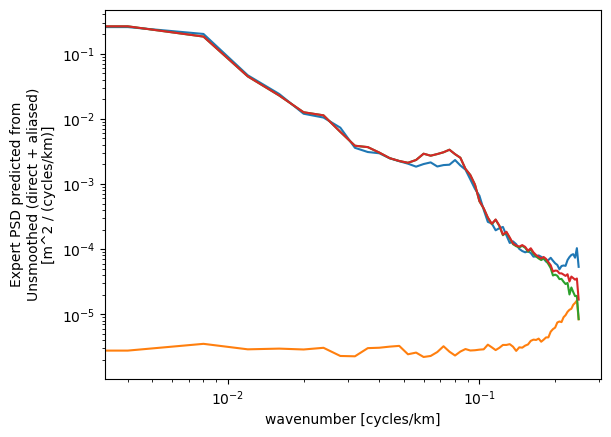

In [110]:
ds_segment.where((ds_segment.lat_mean<=-5) & (ds_segment.lat_mean>=-20),drop=True
                ).mean('segment').expert_psd.plot(xscale='log',yscale='log')
ds_segment.where((ds_segment.lat_mean<=-5) & (ds_segment.lat_mean>=-20),drop=True
                ).mean('segment').aliased_psd.plot(xscale='log',yscale='log')
ds_segment.where((ds_segment.lat_mean<=-5) & (ds_segment.lat_mean>=-20),drop=True
                ).mean('segment').direct_psd.plot(xscale='log',yscale='log')
ds_segment.where((ds_segment.lat_mean<=-5) & (ds_segment.lat_mean>=-20),drop=True
                ).mean('segment').predicted_psd.plot(xscale='log',yscale='log')

In [57]:
ds_segment.lat_mean

<xarray.DataArray 'lat_mean' (segment: 106)> Size: 848B
array([ 17.23628388,  16.18313341,  15.12960451,  14.07582766,
        13.02182375,  11.96750951,  10.91289911,   9.85815033,
         8.80331479,   7.74832211,   6.69312029,   5.63779253,
         4.58244865,   3.52707092,   2.4717247 ,   0.36126801,
       -10.19429378, -13.36102143, -14.41649593, -16.52690703,
       -17.58194343, -18.63683825, -20.74593415, -21.8002063 ,
       -24.96168577, -27.06763185, -28.12000958, -29.17200954,
       -30.22361338, -31.27462011, -32.32498972, -37.56632813,
       -38.61197404, -39.6565036 , -40.69989352, -41.74211914,
       -42.78308725, -43.82261111, -44.86057744, -45.89689991,
       -46.93127104, -47.96353678, -48.99359695, -50.02122809,
       -51.04626346, -52.0685294 , -55.11539155, -56.12287646,
       -57.12573562, -58.12350546, -59.1156781 ,  17.14347749,
        16.09131565,  15.03870951,  13.98579476,  12.93256344,
        11.87895379,  10.82499434,   9.77081085,   8.71647634,
         7.66191795,   6.60709032,   5.5520831 ,   4.49699411,
         3.44179893,   2.38652088,   1.33127613,   0.2760517 ,
        -2.89000065, -10.28187286, -13.4505606 , -14.50679058,
       -17.67493825, -18.73088006, -19.78667008, -20.84229399,
       -21.8978545 , -25.0635829 , -26.11836488, -27.17283401,
       -28.22692758, -29.28072667, -30.33415234, -31.38709061,
       -32.43958699, -33.4915799 , -36.64359615, -37.69279341,
       -38.74124072, -39.78872944, -40.83521639, -41.88066115,
       -42.92497905, -43.96801443, -45.00965553, -46.04980831,
       -47.08817196, -51.22121592, -52.24863527, -53.27333171,
       -54.29485394, -55.31271929, -56.32657436, -57.33613283,
       -58.34099301, -59.34070662])
Coordinates:
  * segment  (segment) int64 848B 0 1 2 3 4 5 6 ... 132 133 134 135 136 137 138
Attributes:
    units:    degrees_north